---

# Tugas Besar 2 IF3170 Inteligensi Artifisial


---

## Group 12

- Muhammad Ashkar (13524007)
- Tengku Naufal Saqib (13524012)
- Rhenaldy Cahyadi Putra (13524039)
- Fayyaz Akmal Lauda (13524076)
- Muhammad Faiz Alfada Dharma (13524097)

---

## Table of Contents

1. [**Introduction**](#1)
2. [**Initialization**](#2)
3. [**Data Understanding (Optional)**](#3)
4. [**Training and Validation Split**](#4)
5. [**Data Preparation**](#5)
6. [**Preparation Pipeline**](#6)
7. [**Modeling and Validation**](#7)
8. [**Comparison with scikit-learn**](#8)
9. [**Saving and Loading Models**](#9)
10. [**Kaggle Submission**](#10)
11. [**Error Analysis**](#11)


---

# Introduction <a name="1"></a>

---

This section frames the problem in the words of the group.

## Overview

Pembatalan pemesanan membuat kamar kosong yang seharusnya bisa terjual ke tamu lain. Memprediksi pembatalan sejak dini membantu penginapan merencanakan overbooking, mengirim pengingat, dan menyusun kebijakan pembatalan yang tepat.

## Aim

Membangun model klasifikasi biner yang memprediksi apakah suatu pemesanan dibatalkan (is_canceled = 1) atau tidak (0). Kelima algoritma (KNN, DTL, Logistic Regression, SVM, Naive Bayes) diimplementasikan from scratch, lalu dibandingkan dengan scikit-learn.

## Metric

Metrik utama adalah macro F1, yaitu rata-rata F1 kelas 0 dan kelas 1. Macro F1 memberi bobot sama pada kedua kelas, sehingga model yang mengabaikan kelas minoritas (batal) mendapat skor rendah walaupun akurasinya tinggi. Seluruh skor pada laporan ini adalah rata-rata macro F1 dari 5-fold Stratified Cross-Validation pada train.csv, kecuali disebutkan lain.

## Dataset

Dataset berisi data reservasi hotel dengan 27.373 baris train dan 6.844 baris test. Terdapat 17 fitur numerik, kategorikal, dan biner, sedangkan is_canceled menjadi target dengan nilai 1 untuk reservasi yang dibatalkan dan 0 untuk yang tidak dibatalkan.

## Approach

Tahapan dimulai dengan EDA, pemeriksaan kualitas data, dan preprocessing melalui imputasi, scaling, serta encoding. Model dievaluasi menggunakan Stratified 5-Fold Cross-Validation, kemudian konfigurasi terbaik dilatih kembali menggunakan seluruh data train untuk menghasilkan prediksi submission.

---

# Initialization <a name="2"></a>

---

This section prepares the environment, the settings, and the data files.

## Environment Setup

The following cell lists the base libraries. The install line is commented by default.

In [2]:
%pip install -q numpy pandas matplotlib seaborn scikit-learn imbalanced-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## Import Libraries

Every import of the notebook is kept in this cell.

In [3]:
import os
import sys
import random
from pathlib import Path
import time

import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold, ParameterGrid
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler, StandardScaler, MinMaxScaler, OneHotEncoder, OrdinalEncoder
from sklearn.decomposition import PCA
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.naive_bayes import CategoricalNB
from sklearn.neighbors import KNeighborsClassifier

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer

from sklearn.metrics import accuracy_score

root = (Path.cwd()if (Path.cwd() / "src").exists()else Path.cwd().parent)
sys.path.insert(0, str(root))

from src.algorithms.knn import KNN
from src.algorithms.decision_tree import DecisionTree
from src.algorithms.logistic_regression import LogisticRegression as ScratchLogisticRegression
from src.algorithms.svm import SVM
from src.algorithms.naive_bayes import NaiveBayes
from sklearn.preprocessing import KBinsDiscretizer
from src.model_io import save_model, load_model

## Settings

Paths and shared constants are kept in this class.

In [4]:
class Settings:
    SEED = 42

    # Kernel dapat berjalan dari root proyek atau folder src.
    PROJECT_DIR = Path.cwd()
    if not (PROJECT_DIR / 'data').exists():
        PROJECT_DIR = PROJECT_DIR.parent

    DATA_DIR = PROJECT_DIR / 'data'
    OUTPUT_DIR = PROJECT_DIR / 'output'

CFG = Settings()
CFG.OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## Seed Everything

A fixed seed keeps the results reproducible.

In [5]:
def seed_everything(seed: int):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)

seed_everything(CFG.SEED)

## Load Dataset

The competition files are read here. The `id` column stays as text because some values resemble numbers.

In [6]:
train_df = pd.read_csv(CFG.DATA_DIR / 'train.csv', dtype={'id': str})
test_df  = pd.read_csv(CFG.DATA_DIR / 'test.csv', dtype={'id': str})

print(f'Train: {train_df.shape}  Test: {test_df.shape}')

Train: (27373, 19)  Test: (6844, 18)


---

# Data Understanding <a name="3"></a>

---

## Describe Data

This part covers the size, the attribute types, and the meaning of each column.

In [7]:
train_df = train_df.drop(columns="id")
test_df = test_df.drop(columns="id")

# ==========================================
# Describe Data
# ==========================================

print("=====================")
print("Train Dataset")
print("=====================")
print(f"Train Dataset: {train_df.shape}")
display(train_df.describe())

print("\n=====================")
print("Test Dataset")
print("=====================")
print(f"Test Dataset: {test_df.shape}")
display(test_df.describe())


Train Dataset
Train Dataset: (27373, 18)


,num_adults,num_children,weekend_nights,weekday_nights,needs_parking,days_before_arrival,arrival_year,arrival_month,arrival_day,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,is_canceled
count,26564.000000,24338.000000,27373.000000,27373.000000,26291.000000,26250.000000,27373.000000,27373.000000,27373.000000,27373.000000,27373.000000,27373.000000,2.533500e+04,24873.000000,27373.000000
mean,1.845242,0.117388,0.814854,2.206517,0.030200,85.379429,2023.820115,7.399664,15.537537,0.025171,0.021883,0.144887,1.716980e+06,0.666948,0.327659
std,0.517974,0.425761,0.875146,1.421603,0.171142,85.969638,0.384099,3.074788,8.773321,0.156646,0.356353,1.693652,5.879368e+05,0.798363,0.469368
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2023.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000
25%,2.000000,0.000000,0.000000,1.000000,0.000000,17.000000,2024.000000,5.000000,8.000000,0.000000,0.000000,0.000000,1.338000e+06,0.000000,0.000000
50%,2.000000,0.000000,1.000000,2.000000,0.000000,58.000000,2024.000000,8.000000,16.000000,0.000000,0.000000,0.000000,1.644000e+06,0.000000,0.000000
75%,2.000000,0.000000,2.000000,3.000000,0.000000,126.000000,2024.000000,10.000000,23.000000,0.000000,0.000000,0.000000,2.019000e+06,1.000000,1.000000
max,4.000000,10.000000,7.000000,17.000000,1.000000,448.000000,2024.000000,12.000000,31.000000,1.000000,13.000000,58.000000,9.165000e+06,5.000000,1.000000



Test Dataset
Test Dataset: (6844, 17)


,num_adults,num_children,weekend_nights,weekday_nights,needs_parking,days_before_arrival,arrival_year,arrival_month,arrival_day,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests
count,6664.000000,6097.000000,6844.000000,6844.000000,6597.000000,6554.000000,6844.000000,6844.000000,6844.000000,6844.000000,6844.000000,6844.000000,6.304000e+03,6251.000000
mean,1.844088,0.119567,0.796610,2.205435,0.033500,85.365426,2023.818235,7.401812,15.702659,0.027323,0.031414,0.181911,1.714169e+06,0.670613
std,0.519615,0.422822,0.858793,1.379860,0.179952,85.989244,0.385679,3.050240,8.681514,0.163035,0.444205,1.917124,5.712354e+05,0.792443
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2023.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000
25%,2.000000,0.000000,0.000000,1.000000,0.000000,17.000000,2024.000000,5.000000,8.000000,0.000000,0.000000,0.000000,1.340000e+06,0.000000
50%,2.000000,0.000000,1.000000,2.000000,0.000000,57.000000,2024.000000,8.000000,16.000000,0.000000,0.000000,0.000000,1.643000e+06,0.000000
75%,2.000000,0.000000,2.000000,3.000000,0.000000,125.000000,2024.000000,10.000000,23.000000,0.000000,0.000000,0.000000,2.010250e+06,1.000000
max,4.000000,3.000000,6.000000,17.000000,1.000000,443.000000,2024.000000,12.000000,31.000000,1.000000,13.000000,53.000000,5.700000e+06,5.000000


In [8]:
# ==========================================
# Data Types
# ==========================================
display(train_df.dtypes.to_frame(name="dtype"))

,dtype
num_adults,float64
num_children,float64
weekend_nights,int64
weekday_nights,int64
meal_package,object
needs_parking,float64
room_category,object
days_before_arrival,float64
arrival_year,int64
arrival_month,int64


## Explore Data

This part covers distributions and relationships between attributes.

In [9]:
# ==========================================
# EXPLORE DATA
# ==========================================

# Identify all the columns
# Numerical Columns
numerical_cols = [
    "num_adults",
    "num_children",
    "weekend_nights",
    "weekday_nights",
    "days_before_arrival",
    "prior_cancellations",
    "prior_completed_bookings",
    "nightly_rate_idr",
    "special_requests",
    "arrival_year",
    "arrival_month",
    "arrival_day"
]

# Categorical Columns
categorical_cols = [
    "meal_package",
    "needs_parking",
    "room_category",
    "booking_channel",
    "is_returning_guest"
]

# Target Columns
target_cols = [
    "is_canceled"
]


Distribusi Data Target



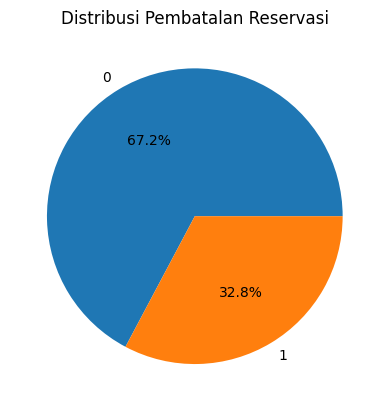

In [10]:
# ==========================================
# DISTRIBUSI DATA TARGET
# ==========================================
n_cols = 3
n_rows = math.ceil(len(numerical_cols) / n_cols)

print("\n=============================================")
print("Distribusi Data Target")
print("=============================================\n")

train_df["is_canceled"].value_counts().plot.pie(autopct="%.1f%%", ylabel="")
plt.title("Distribusi Pembatalan Reservasi")
plt.show()

### Insights

Sebanyak 18.404 reservasi (67,23%) tidak dibatalkan (`is_canceled = 0`), sedangkan 8.969 reservasi (32,77%) dibatalkan (`is_canceled = 1`). Dengan demikian, sekitar dua dari setiap tiga reservasi tetap berlangsung dan satu dari setiap tiga reservasi dibatalkan.


Distribusi Data Numerik



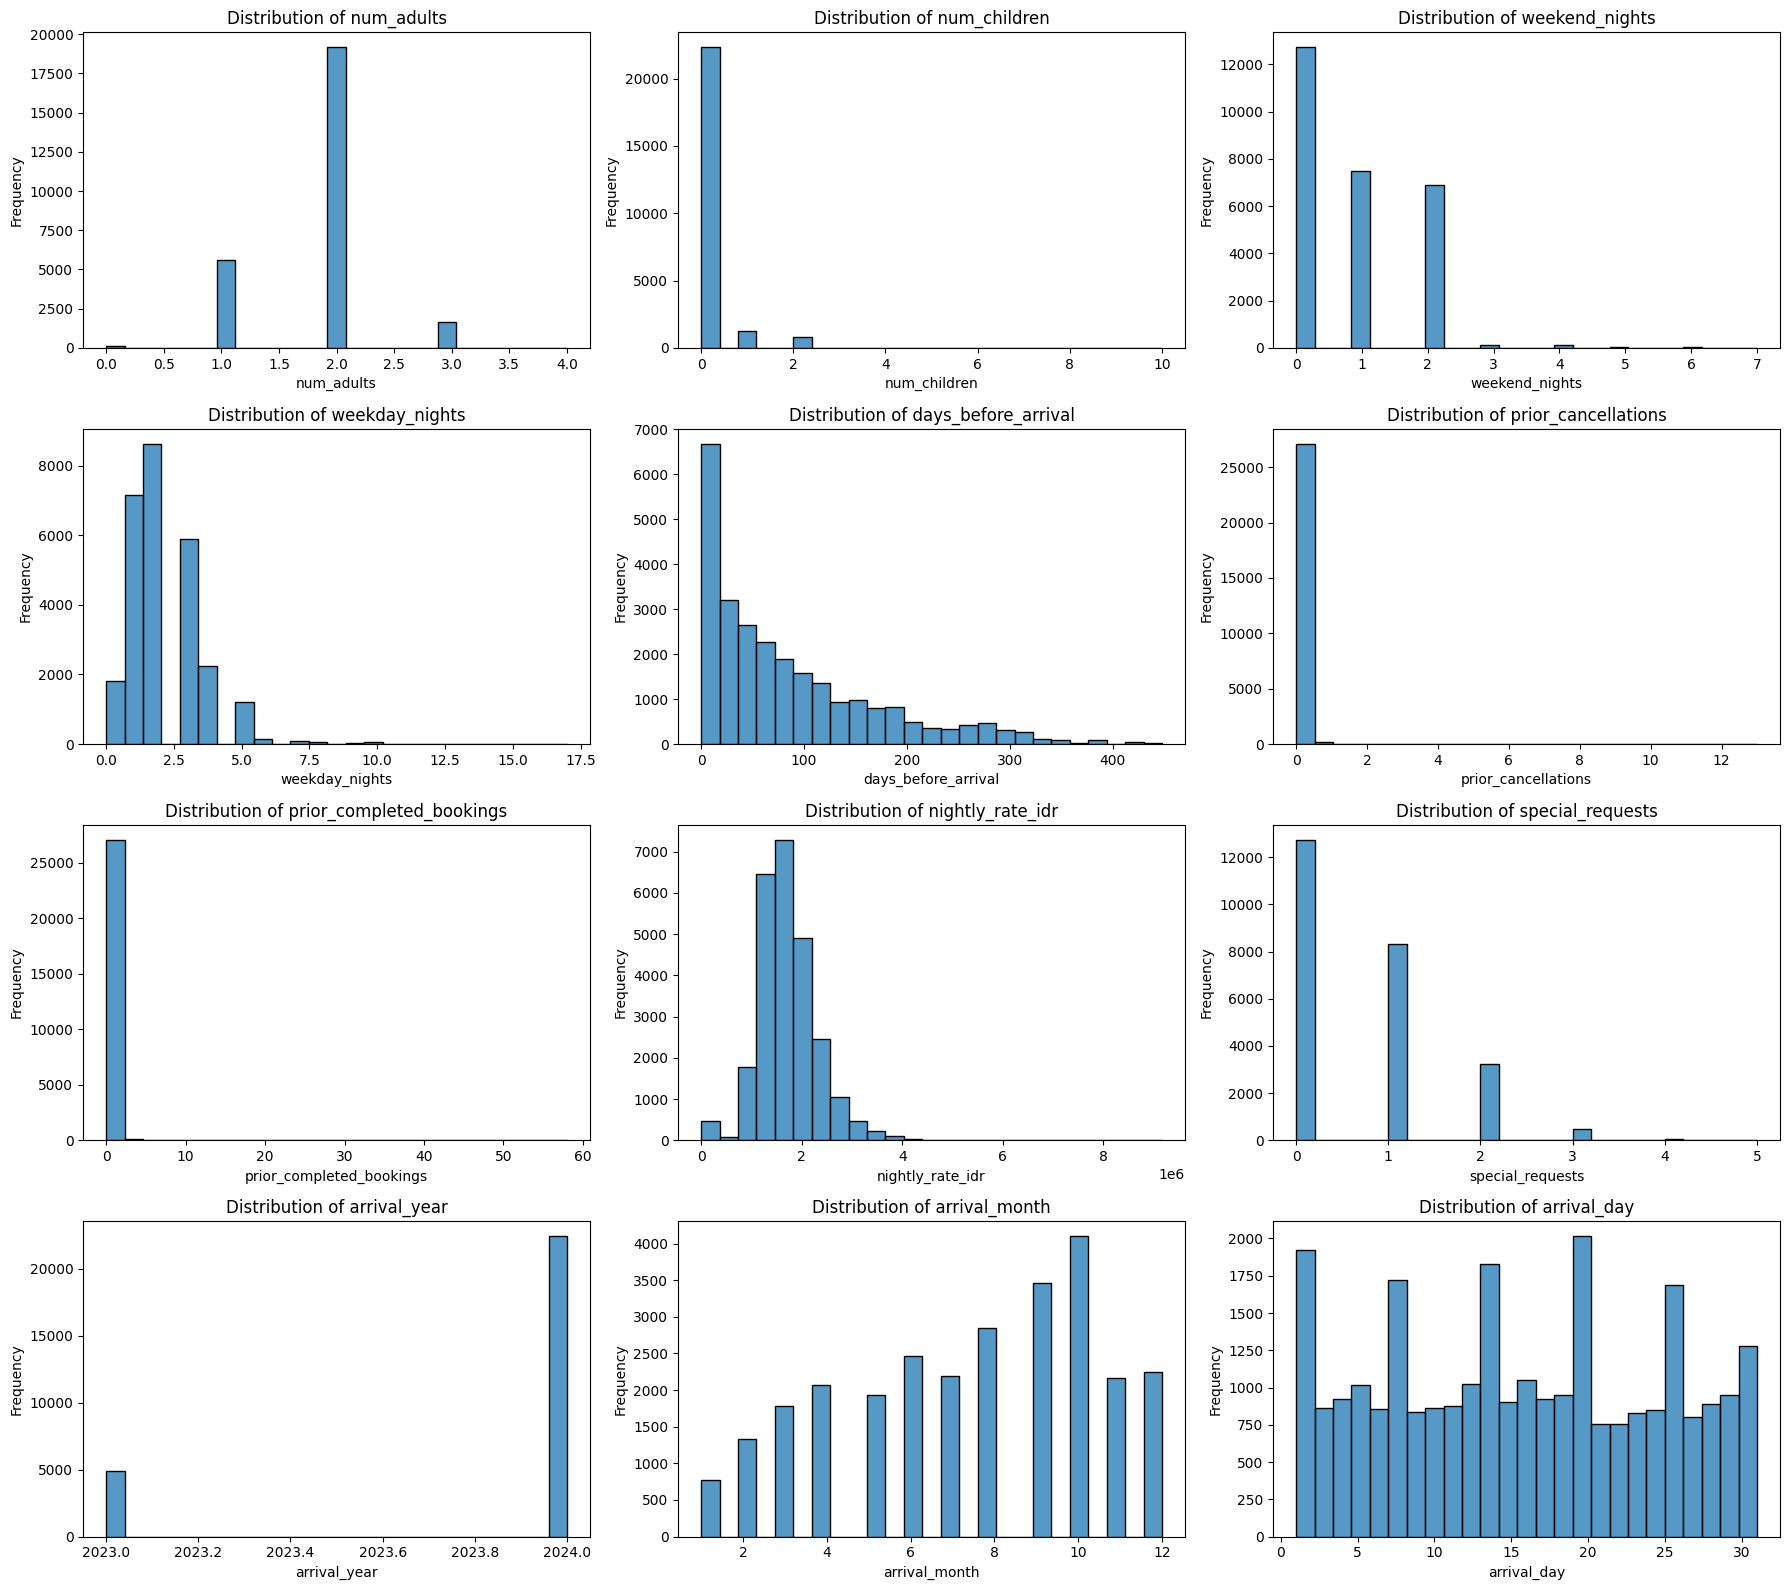

In [11]:
# ==========================================
# DISTRIBUSI DATA NUMERIK
# ==========================================

print("\n=============================================")
print("Distribusi Data Numerik")
print("=============================================\n")

fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 4 * n_rows))
axes = axes.flatten()
for i, col in enumerate(numerical_cols):
    sns.histplot(data=train_df, x=col, bins=25, ax=axes[i])
    axes[i].set_title(f"Distribution of {col}")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Frequency")

for i in range(len(numerical_cols), len(axes)):
    axes[i].set_visible(False)

plt.tight_layout()
plt.show()

### Insights

- Jumlah tamu dewasa berada pada rentang 0–4 orang, dengan rata-rata 1,85 orang dan nilai tengah 2 orang.
- Sebanyak 81,53% reservasi tidak membawa anak-anak. Jumlah anak berada pada rentang 0–10 orang, dengan rata-rata 0,12 orang.
- Jumlah malam akhir pekan memiliki rata-rata 0,81 malam dan maksimum 7 malam. Sebanyak 46,45% reservasi tidak mencakup malam akhir pekan.
- Jumlah malam hari kerja memiliki rata-rata 2,21 malam, nilai tengah 2 malam, dan maksimum 17 malam.
- Jarak antara waktu pemesanan dan kedatangan berada pada rentang 0–448 hari. Rata-ratanya adalah 85,38 hari, sedangkan nilai tengahnya 58 hari.
- Sebanyak 99,12% reservasi tidak memiliki riwayat pembatalan sebelumnya.
- Sebanyak 97,81% reservasi tidak memiliki riwayat reservasi selesai sebelumnya.
- Harga kamar per malam memiliki rata-rata sekitar Rp1,72 juta dan nilai tengah sekitar Rp1,64 juta. Nilainya berada pada rentang Rp0–Rp9,17 juta.
- Jumlah permintaan khusus berada pada rentang 0–5 permintaan, dengan rata-rata 0,67 permintaan. Sebanyak 46,51% reservasi tidak memiliki permintaan khusus.
- Data kedatangan berasal dari tahun 2023 dan 2024, dengan sekitar 82% reservasi dijadwalkan pada tahun 2024.
- Bulan kedatangan tersebar dari Januari hingga Desember, dengan nilai tengah pada bulan Agustus.
- Tanggal kedatangan tersebar dari tanggal 1–31, dengan nilai tengah pada tanggal 16.


Distribusi Data Kategorikal



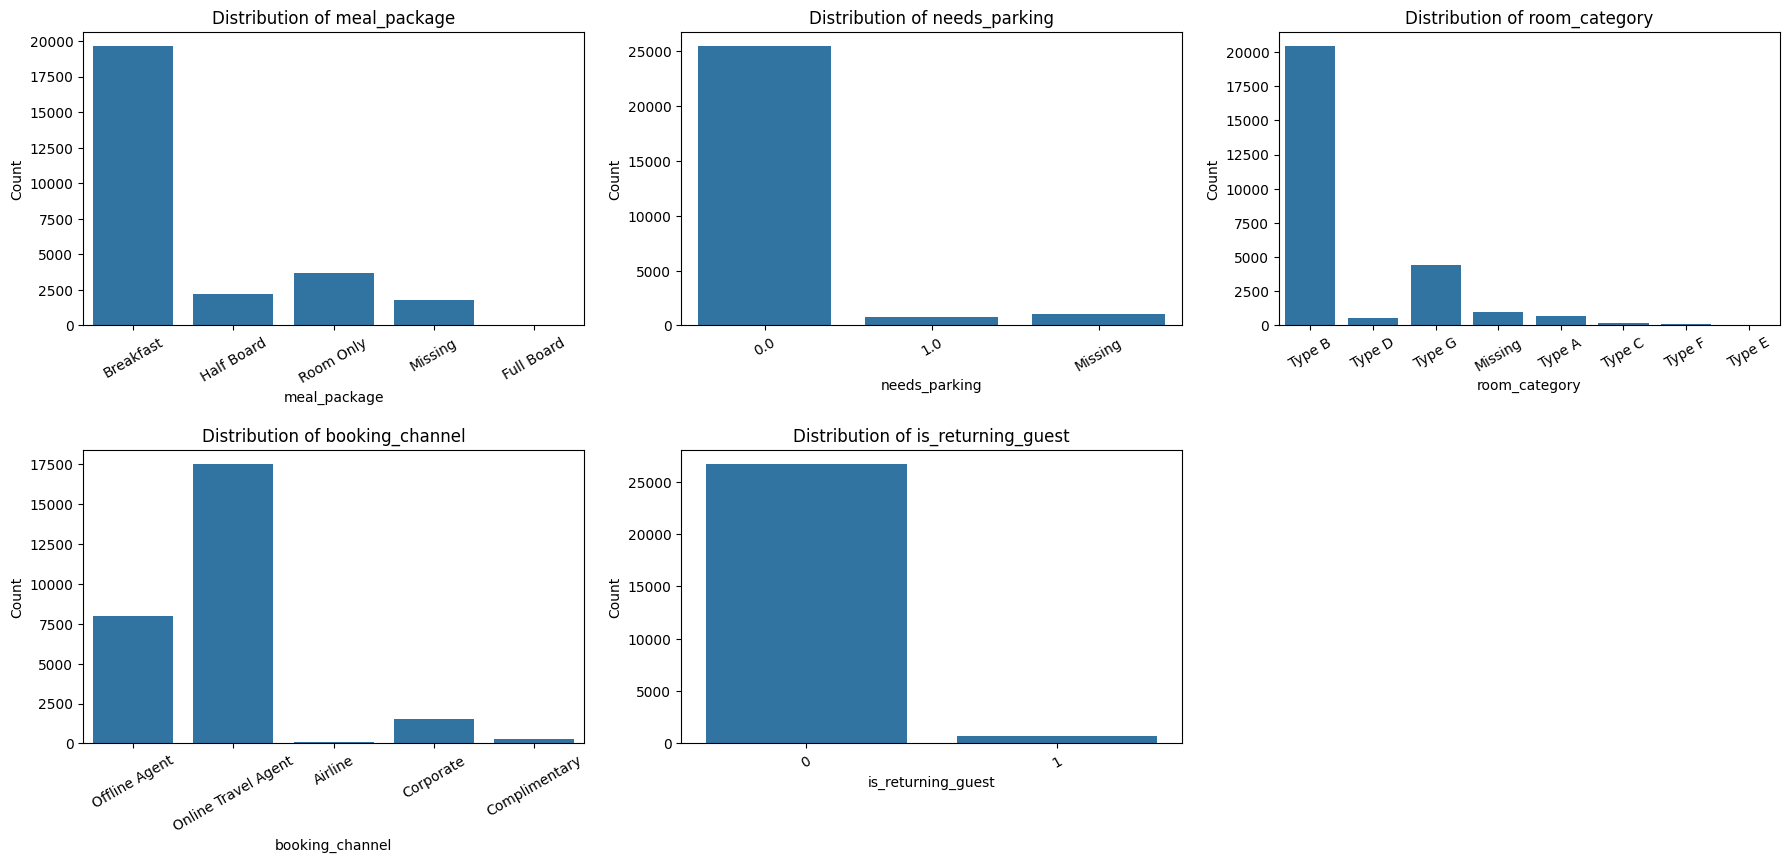

In [12]:
# ==========================================
# DISTRIBUSI DATA KATEGORIKAL
# ==========================================

print("\n=============================================")
print("Distribusi Data Kategorikal")
print("=============================================\n")

fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 4 * n_rows), squeeze=False)
axes = axes.flatten()
for i, col in enumerate(categorical_cols):
    sns.countplot(x=train_df[col].fillna("Missing").astype(str), ax=axes[i])
    axes[i].set_title(f"Distribution of {col}")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Count")
    axes[i].tick_params(axis="x", rotation=30)

for i in range(len(categorical_cols), len(axes)):
    axes[i].set_visible(False)

plt.tight_layout()
plt.show()

### Insights

- Paket makanan didominasi oleh Breakfast sebanyak 19.654 reservasi (71,80%). Kategori lainnya adalah Room Only sebesar 13,56%, Half Board sebesar 8,19%, missing value sebesar 6,43%, dan Full Board sebesar 0,01%.
- Sebanyak 93,15% reservasi tidak membutuhkan tempat parkir, sedangkan 2,90% membutuhkan tempat parkir. Sisanya, yaitu 3,95%, tidak memiliki informasi kebutuhan parkir.
- Kategori kamar paling banyak adalah Type B sebesar 74,70%, diikuti Type G sebesar 16,06%. Kategori kamar lainnya masing-masing memiliki proporsi di bawah 3%, sedangkan 3,66% data tidak memiliki informasi kategori kamar.
- Saluran pemesanan didominasi oleh Online Travel Agent sebesar 63,97%, diikuti Offline Agent sebesar 29,08%, Corporate sebesar 5,53%, Complimentary sebesar 1,10%, dan Airline sebesar 0,32%.
- Sebanyak 97,48% reservasi dibuat oleh tamu yang bukan returning guest. Returning guest mencakup 2,52% dari seluruh data.


Hubungan Data Numerik dengan Target



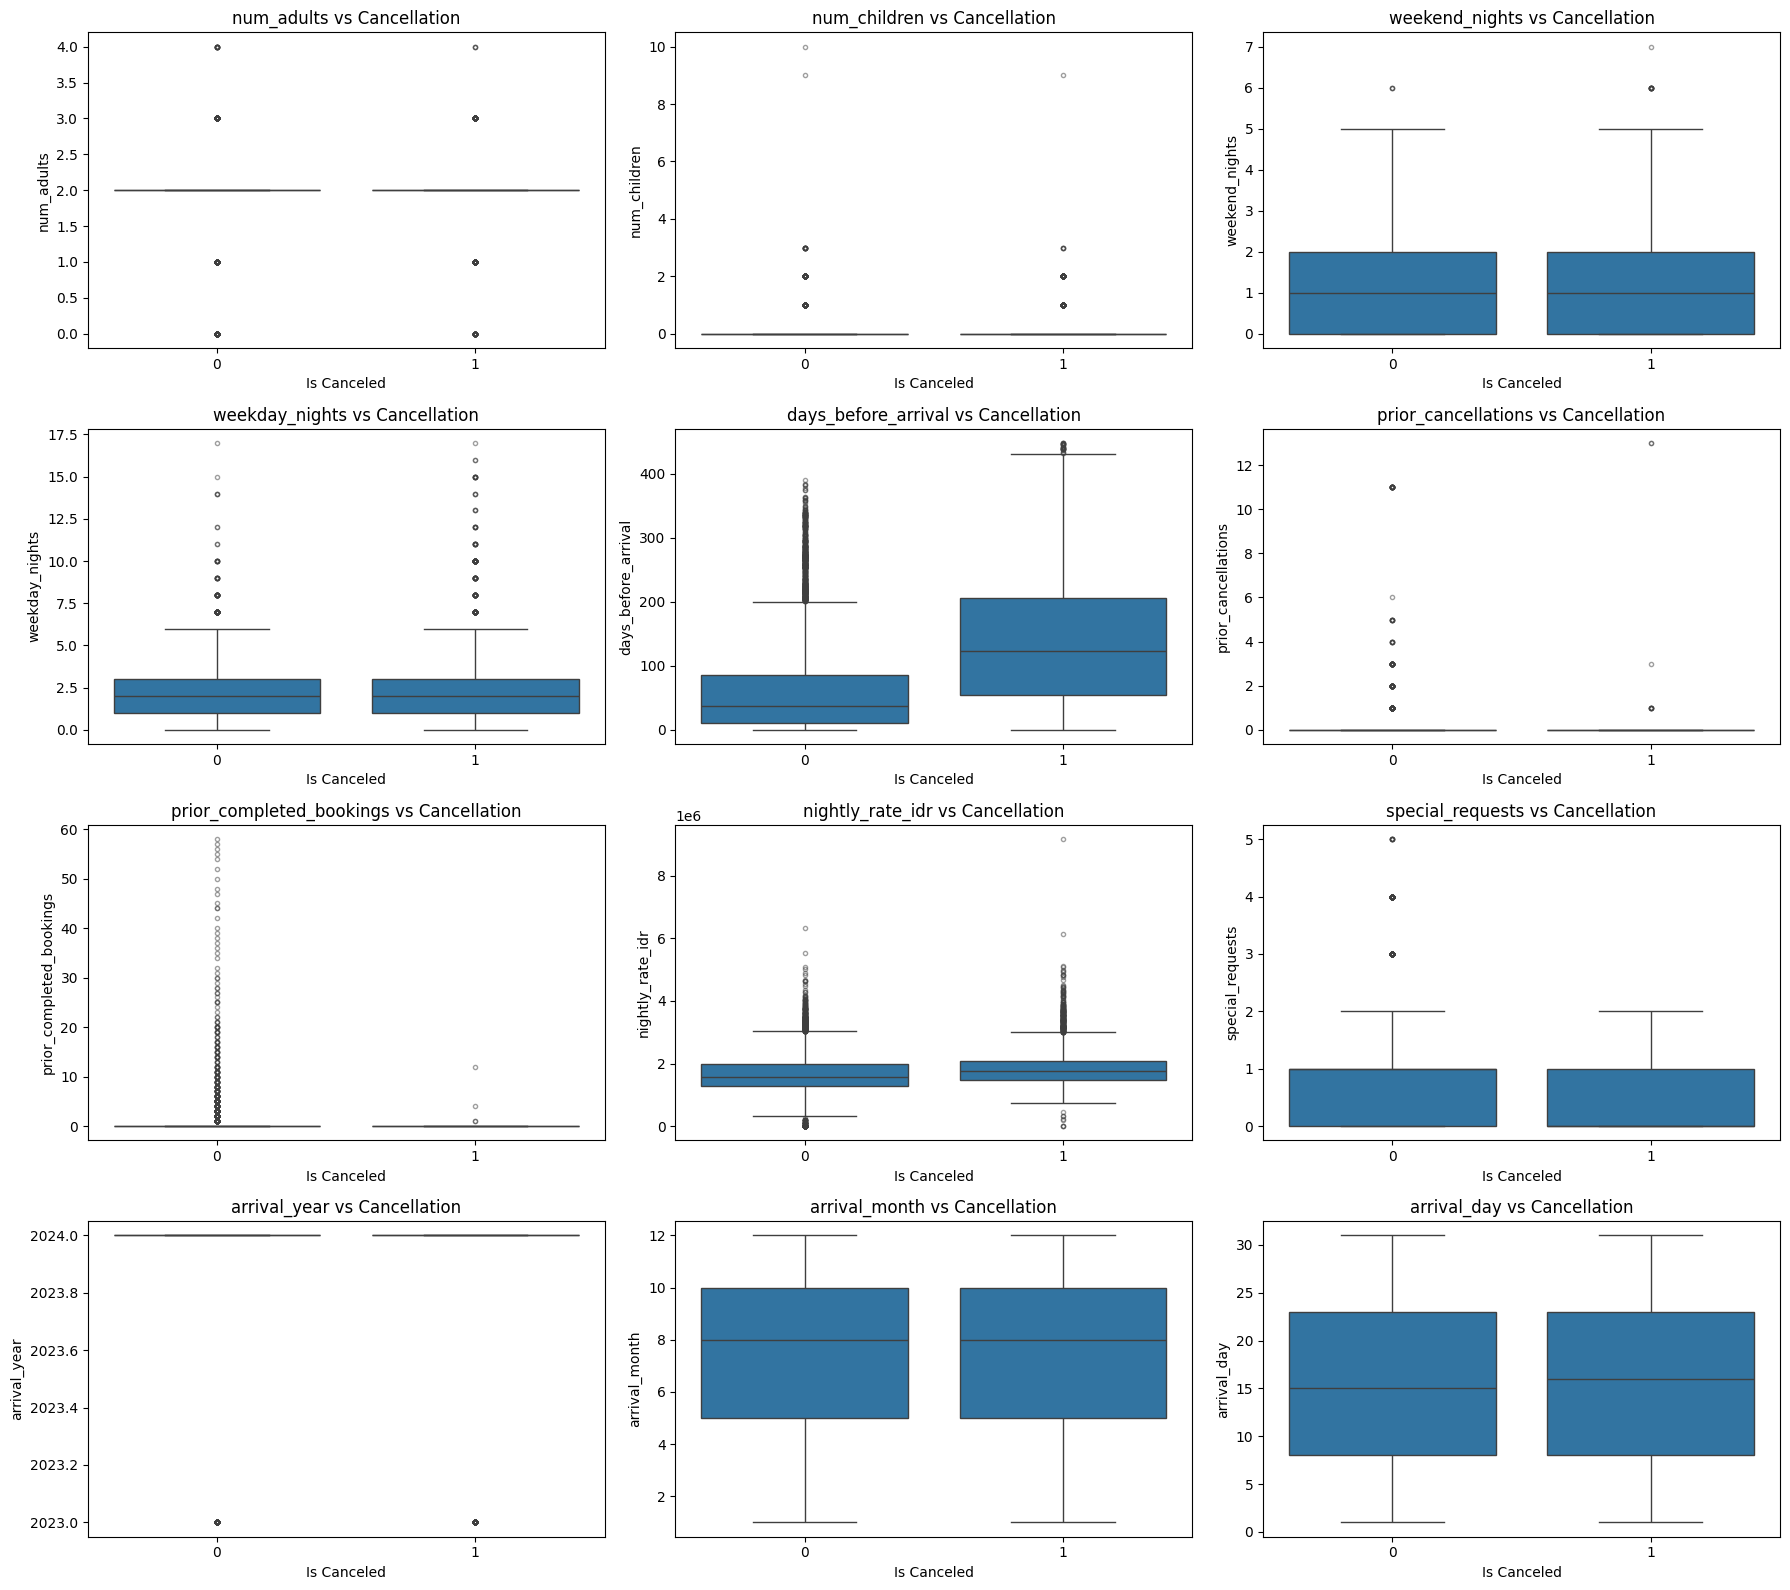

In [13]:
# ==========================================
# HUBUNGAN DATA NUMERIK DENGAN TARGET
# ==========================================

print("\n=============================================")
print("Hubungan Data Numerik dengan Target")
print("=============================================\n")

fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 4 * n_rows), squeeze=False)
axes = axes.flatten()
for i, col in enumerate(numerical_cols):
    sns.boxplot(data=train_df, x="is_canceled", y=col, showfliers=True,
        flierprops = {
            "marker": "o",
            "markersize": 3,
            "alpha": 0.5
        },
        ax=axes[i]
    )

    axes[i].set_title(f"{col} vs Cancellation")
    axes[i].set_xlabel("Is Canceled")
    axes[i].set_ylabel(col)

for i in range(len(numerical_cols), len(axes)):
    axes[i].set_visible(False)

plt.tight_layout()
plt.show()

### Insights

- Reservasi yang dibatalkan memiliki rata-rata jarak pemesanan ke kedatangan sebesar 139,52 hari, sedangkan reservasi yang tidak dibatalkan memiliki rata-rata 58,91 hari. Nilai tengahnya masing-masing adalah 123 hari dan 38 hari.
- Rata-rata jumlah permintaan khusus pada reservasi yang tidak dibatalkan adalah 0,81, sedangkan pada reservasi yang dibatalkan sebesar 0,37. Nilai tengahnya masing-masing adalah 1 dan 0.
- Reservasi yang dibatalkan memiliki rata-rata harga kamar sekitar Rp1,83 juta per malam, sedangkan reservasi yang tidak dibatalkan memiliki rata-rata sekitar Rp1,66 juta per malam.
- Rata-rata jumlah malam hari kerja adalah 2,40 malam untuk reservasi yang dibatalkan dan 2,11 malam untuk reservasi yang tidak dibatalkan.
- Rata-rata jumlah malam akhir pekan adalah 0,89 malam untuk reservasi yang dibatalkan dan 0,78 malam untuk reservasi yang tidak dibatalkan.
- Kedua kelas memiliki nilai tengah jumlah tamu dewasa yang sama, yaitu 2 orang, serta nilai tengah jumlah anak yang sama, yaitu 0 orang.
- Reservasi yang tidak dibatalkan memiliki rata-rata riwayat reservasi selesai sebesar 0,21, sedangkan reservasi yang dibatalkan memiliki rata-rata mendekati 0.
- Nilai tengah bulan kedatangan pada kedua kelas adalah bulan Agustus. Nilai tengah tanggal kedatangan adalah tanggal 15 untuk reservasi yang tidak dibatalkan dan tanggal 16 untuk reservasi yang dibatalkan.


Hubungan Data Kategorikal dengan Target



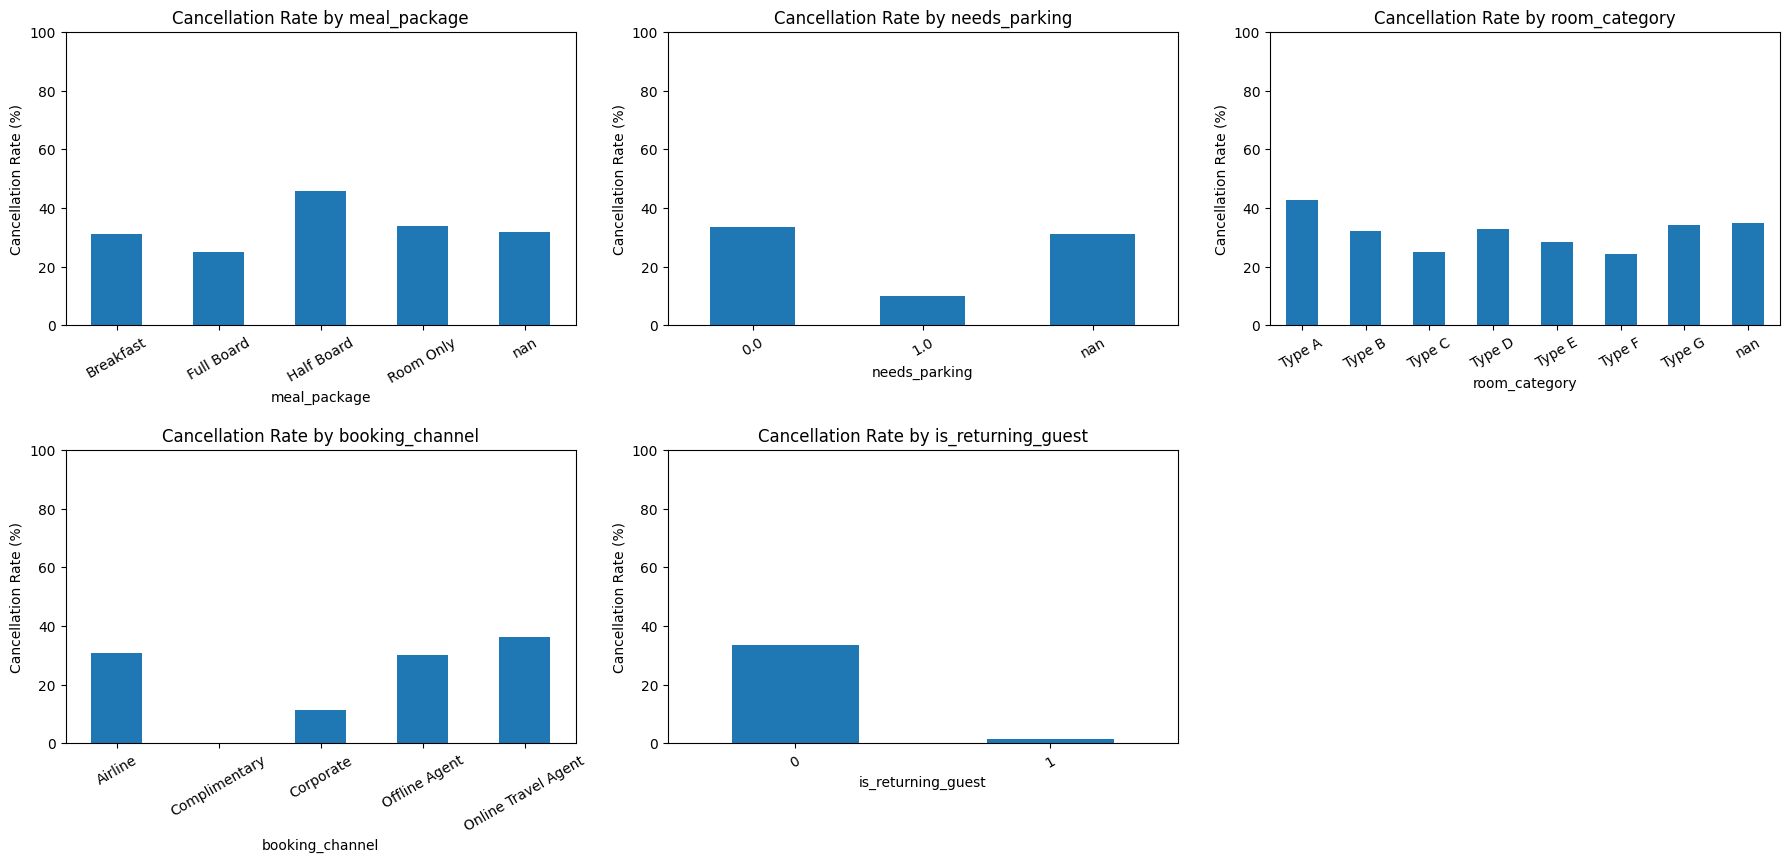

In [14]:
# ==========================================
# HUBUNGAN DATA KATEGORIKAL DENGAN TARGET
# ==========================================

print("\n=============================================")
print("Hubungan Data Kategorikal dengan Target")
print("=============================================\n")

fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 4 * n_rows), squeeze=False)
axes = axes.flatten()
for i, col in enumerate(categorical_cols):
    cancel_rate = (train_df.groupby(col, dropna=False)["is_canceled"].mean().mul(100))
    cancel_rate.plot(kind="bar", ax=axes[i])
    axes[i].set_title(f"Cancellation Rate by {col}")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Cancellation Rate (%)")
    axes[i].tick_params(axis="x", rotation=30)
    axes[i].set_ylim(0, 100)

for i in range(len(categorical_cols), len(axes)):
    axes[i].set_visible(False)

plt.tight_layout()
plt.show()

### Insights

- Pada atribut paket makanan, Half Board memiliki persentase pembatalan sebesar 45,94%, Room Only sebesar 33,80%, Breakfast sebesar 31,14%, dan data tanpa informasi paket makanan sebesar 31,93%. Full Board memiliki persentase pembatalan sebesar 25%, tetapi hanya terdiri dari 4 reservasi.
- Reservasi yang tidak membutuhkan tempat parkir memiliki persentase pembatalan sebesar 33,54%. Reservasi yang membutuhkan tempat parkir memiliki persentase pembatalan sebesar 10,08%, sedangkan data tanpa informasi parkir sebesar 31,24%.
- Type A memiliki persentase pembatalan sebesar 42,63%. Type G, Type D, dan Type B masing-masing memiliki persentase pembatalan sebesar 34,19%, 32,88%, dan 32,14%.
- Type C dan Type F memiliki persentase pembatalan masing-masing sebesar 24,87% dan 24,37%. Type E memiliki persentase pembatalan sebesar 28,57%, tetapi hanya terdiri dari 7 reservasi.
- Online Travel Agent memiliki persentase pembatalan sebesar 36,37%, Airline sebesar 30,68%, dan Offline Agent sebesar 30,15%.
- Reservasi melalui Corporate memiliki persentase pembatalan sebesar 11,50%, sedangkan reservasi Complimentary tidak mengalami pembatalan dalam dataset.
- Tamu yang bukan returning guest memiliki persentase pembatalan sebesar 33,57%, sedangkan returning guest memiliki persentase pembatalan sebesar 1,45%.


Hubungan Antaratribut Numerik dengan Heatmap



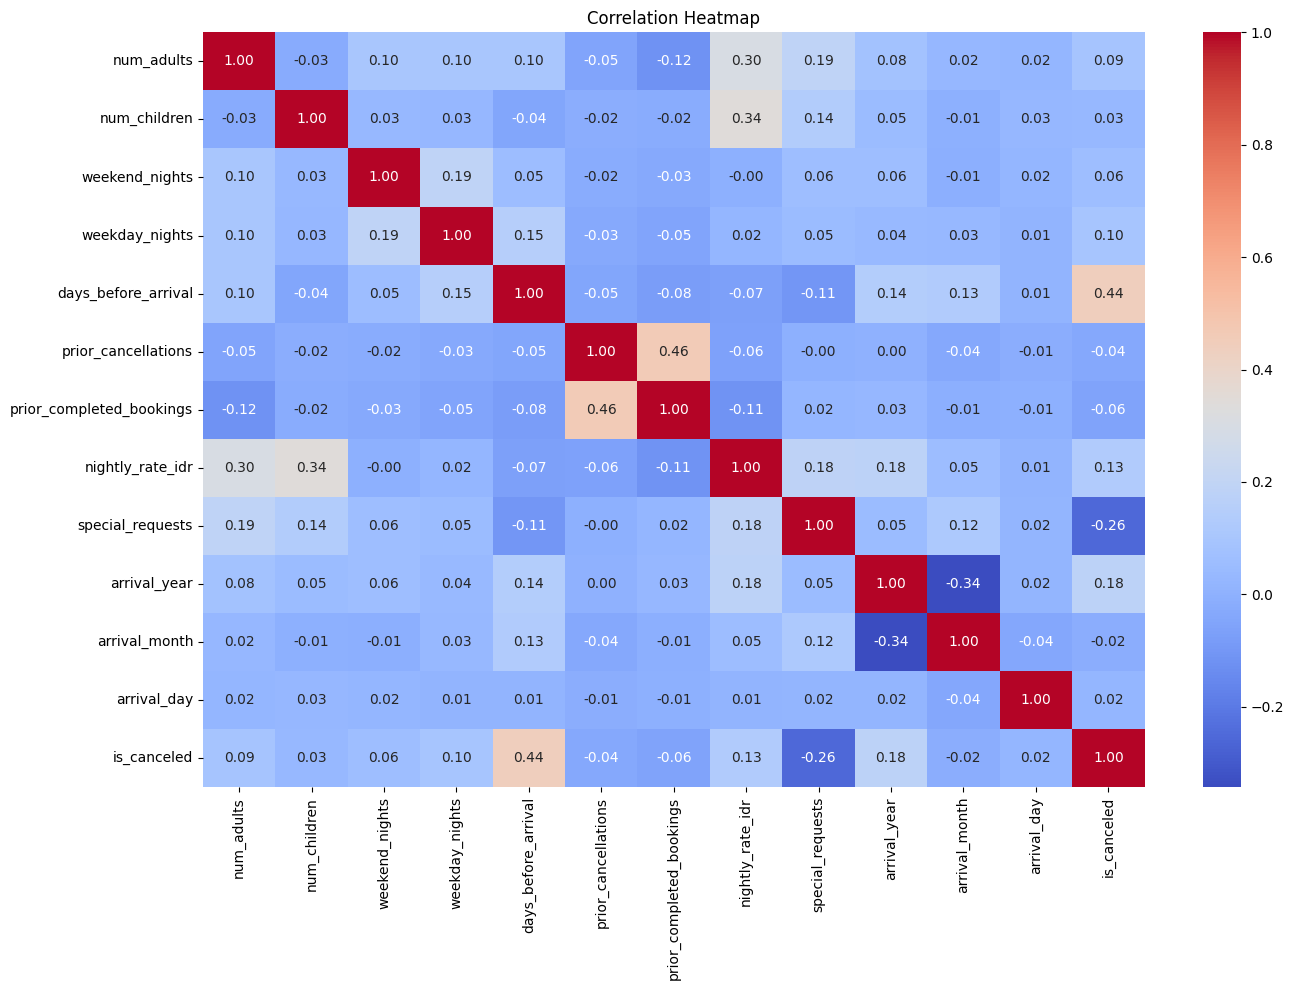

,Feature,Correlation
0,days_before_arrival,0.440316
1,special_requests,-0.257996
2,arrival_year,0.179826
3,nightly_rate_idr,0.134092
4,is_returning_guest,-0.107207
5,weekday_nights,0.097226
6,num_adults,0.088446
7,needs_parking,-0.085504
8,weekend_nights,0.060797
9,prior_completed_bookings,-0.058894


In [15]:
# ==========================================
# KORELASI ANTARATRIBUT NUMERIK
# ==========================================

print("\n=============================================")
print("Hubungan Antaratribut Numerik dengan Heatmap")
print("=============================================\n")
# Korelasi antar atribut pada Heatmap
corr_cols = numerical_cols + target_cols
correlation = train_df[corr_cols].corr()

plt.figure(figsize=(14, 10))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

# Urutan korelasi atribut dengan target dari yg terbesar
correlation = (train_df.select_dtypes(include="number").drop(columns="is_canceled").corrwith(train_df["is_canceled"]).sort_values(key=abs, ascending=False))
correlation_table = correlation.rename_axis("Feature").reset_index(name="Correlation")
display(correlation_table)

### Insights

- `days_before_arrival` memiliki korelasi positif sebesar 0,4403 dengan `is_canceled`.
- `special_requests` memiliki korelasi negatif sebesar -0,2580 dengan `is_canceled`.
- `arrival_year` memiliki korelasi sebesar 0,1798, sedangkan `nightly_rate_idr` memiliki korelasi sebesar 0,1341 dengan `is_canceled`.
- `weekday_nights`, `num_adults`, dan `weekend_nights` memiliki korelasi masing-masing sebesar 0,0972, 0,0884, dan 0,0608 dengan `is_canceled`.
- `prior_completed_bookings` memiliki korelasi sebesar -0,0589, sedangkan `prior_cancellations` memiliki korelasi sebesar -0,0350 dengan `is_canceled`.
- `num_children`, `arrival_day`, dan `arrival_month` memiliki korelasi yang mendekati nol dengan `is_canceled`.
- Di antara sesama atribut, korelasi tertinggi terdapat antara `prior_cancellations` dan `prior_completed_bookings`, yaitu sebesar 0,4639.
- `arrival_year` dan `arrival_month` memiliki korelasi sebesar -0,3431.
- `num_children` dan `nightly_rate_idr` memiliki korelasi sebesar 0,3390.
- `num_adults` dan `nightly_rate_idr` memiliki korelasi sebesar 0,3002.
- Sebagian besar pasangan atribut numerik lainnya memiliki nilai korelasi yang relatif rendah.

## Verify Data Quality

This part covers completeness, consistency, and the validity of values.

In [16]:
# ==========================================
# Check missing values
# ==========================================

# Memeriksa missing values pada train dan test
print("\n=============================================")
print("Missing Values")
print("=============================================\n")

missing_train = train_df.isnull().sum()
missing_test = test_df.isnull().sum()

print(f"Missing Values - Train")
display(missing_train.to_frame(name="count_missing"))

print(f"Missing Values - Test")
display(missing_train.to_frame(name="count_missing"))


Missing Values

Missing Values - Train


,count_missing
num_adults,809
num_children,3035
weekend_nights,0
weekday_nights,0
meal_package,1760
needs_parking,1082
room_category,1002
days_before_arrival,1123
arrival_year,0
arrival_month,0


Missing Values - Test


,count_missing
num_adults,809
num_children,3035
weekend_nights,0
weekday_nights,0
meal_package,1760
needs_parking,1082
room_category,1002
days_before_arrival,1123
arrival_year,0
arrival_month,0


In [17]:
# ==========================================
# Check Duplicate Value
# ==========================================

# Memeriksa data-data yangduplikat
print("\n=============================================")
print("Duplicate Data")
print("=============================================\n")

display(train_df[train_df.duplicated(keep= False)])
print(f"Duplicated Train: {train_df.duplicated().sum()}")
display(train_df[train_df.duplicated(keep= False)])
print(f"Duplicated Test: {test_df.duplicated().sum()}")


Duplicate Data



,num_adults,num_children,weekend_nights,weekday_nights,meal_package,needs_parking,room_category,days_before_arrival,arrival_year,arrival_month,arrival_day,booking_channel,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,is_canceled
320,2.0,0.0,0,2,Half Board,0.0,Type B,77.0,2023,9,18,Offline Agent,0,0,0,1763000.0,0.0,0
932,2.0,0.0,0,3,Breakfast,0.0,Type B,38.0,2024,10,12,Offline Agent,0,0,0,NaN,0.0,0
1003,2.0,0.0,0,1,Breakfast,0.0,Type B,39.0,2023,10,23,Online Travel Agent,0,0,0,0.0,0.0,0
1109,1.0,0.0,0,3,Breakfast,0.0,Type B,NaN,2024,6,13,Offline Agent,0,0,0,NaN,0.0,0
1134,2.0,0.0,1,1,Breakfast,0.0,Type B,184.0,2024,5,1,Offline Agent,0,0,0,NaN,1.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26440,1.0,0.0,0,3,Breakfast,0.0,Type B,164.0,2024,10,31,Offline Agent,0,0,0,1763000.0,0.0,1
26766,2.0,0.0,0,2,Half Board,0.0,Type B,351.0,2024,9,12,Offline Agent,0,0,0,NaN,1.0,1
26912,2.0,0.0,0,2,Half Board,0.0,Type B,76.0,2023,9,18,Offline Agent,0,0,0,NaN,0.0,0
27050,2.0,0.0,2,1,Half Board,0.0,Type B,143.0,2023,8,29,Offline Agent,0,0,0,NaN,0.0,0


Duplicated Train: 64


,num_adults,num_children,weekend_nights,weekday_nights,meal_package,needs_parking,room_category,days_before_arrival,arrival_year,arrival_month,arrival_day,booking_channel,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,is_canceled
320,2.0,0.0,0,2,Half Board,0.0,Type B,77.0,2023,9,18,Offline Agent,0,0,0,1763000.0,0.0,0
932,2.0,0.0,0,3,Breakfast,0.0,Type B,38.0,2024,10,12,Offline Agent,0,0,0,NaN,0.0,0
1003,2.0,0.0,0,1,Breakfast,0.0,Type B,39.0,2023,10,23,Online Travel Agent,0,0,0,0.0,0.0,0
1109,1.0,0.0,0,3,Breakfast,0.0,Type B,NaN,2024,6,13,Offline Agent,0,0,0,NaN,0.0,0
1134,2.0,0.0,1,1,Breakfast,0.0,Type B,184.0,2024,5,1,Offline Agent,0,0,0,NaN,1.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26440,1.0,0.0,0,3,Breakfast,0.0,Type B,164.0,2024,10,31,Offline Agent,0,0,0,1763000.0,0.0,1
26766,2.0,0.0,0,2,Half Board,0.0,Type B,351.0,2024,9,12,Offline Agent,0,0,0,NaN,1.0,1
26912,2.0,0.0,0,2,Half Board,0.0,Type B,76.0,2023,9,18,Offline Agent,0,0,0,NaN,0.0,0
27050,2.0,0.0,2,1,Half Board,0.0,Type B,143.0,2023,8,29,Offline Agent,0,0,0,NaN,0.0,0


Duplicated Test: 3


- Kelas tidak seimbang. 18.404 baris (67,2%) tidak batal dan 8.969 baris (32,8%) batal. Model yang selalu menebak kelas mayoritas sudah mendapat akurasi 67%, sehingga akurasi bukan metrik yang tepat.
- Missing value ada di delapan kolom, terbanyak num_children (11,1%). Proporsinya hampir sama di train dan test (selisih di bawah 0,5 poin persen), sehingga strategi imputasi dari data train aman diterapkan ke test.
- Missing yang informatif. Pemesanan dengan special_requests kosong batal 40,8%, dibanding 32,0% bila terisi.
- Nilai ekstrem yang valid. nightly_rate_idr = 0 muncul pada 413 baris, 267 di antaranya berasal dari kanal Complimentary (median harganya memang 0) dan hampir tidak pernah batal (0,7%). prior_completed_bookings mencapai 58, tamu dengan nilai lebih dari 0 hanya batal 0,7%. Nilai-nilai ini merupakan sinyal, bukan kesalahan data, sehingga tidak dibuang.
- Duplikat. Terdapat 64 baris identik (tanpa id) dengan label yang selalu sama, sehingga tidak menimbulkan konflik dan dipertahankan.
- Kategori langka. Full Board hanya 4 baris dan Type E hanya 7 baris, sehingga encoder harus tahan terhadap kategori yang tidak muncul di salah satu fold.

---

# Training and Validation Split <a name="4"></a>

---

The split comes before data preparation so that validation data stays unseen. Only `train.csv` is split, and `test.csv` serves the Kaggle submission alone.

In [18]:
# ==========================================
# TRAINING AND VALIDATION SPLIT
# ==========================================

N_SPLITS = 5

selected_cols = numerical_cols + categorical_cols

X = train_df[selected_cols].copy()
y = train_df["is_canceled"].copy()

x_test = test_df[selected_cols].copy()

# ==========================================
# STRATIFIED K-FOLD
# ==========================================

cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=42)

folds = list(cv.split(X, y))
train_idx, val_idx = folds[1]

x_train = X.iloc[train_idx].copy()
x_val = X.iloc[val_idx].copy()
y_train = y.iloc[train_idx].copy()
y_val = y.iloc[val_idx].copy()

print("\n=============================================")
print("Training and Validation Strategy")
print("=============================================\n")

print("Training Data  :", x_train.shape)
print("Validation Data:", x_val.shape)
print("Test Data      :", x_test.shape)


Training and Validation Strategy

Training Data  : (21898, 17)
Validation Data: (5475, 17)
Test Data      : (6844, 17)


Data dibagi sebelum preprocessing untuk mencegah data leakage. Stratified K-Fold dalam pembagian data menjadi data train dan data validation digunakan agar proporsi kelas tetap terjaga pada data training dan validation. Satu dari lima fold digunakan untuk validation sehingga pembagiannya sekitar 80:20.

---

# Data Preparation <a name="5"></a>

---

## Select Data

Selection decides which records and attributes stay in the analysis.

In [19]:
# ==========================================
# SELECT DATA
# ==========================================

# Memilih atribut yang digunakan sebagai fitur
display(x_train.head())
display(x_val.head())
display(x_test.head())

,num_adults,num_children,weekend_nights,weekday_nights,days_before_arrival,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,arrival_year,arrival_month,arrival_day,meal_package,needs_parking,room_category,booking_channel,is_returning_guest
0,2.0,NaN,1,2,88.0,0,0,1330000.0,0.0,2024,4,3,Breakfast,0.0,Type B,Offline Agent,0
1,2.0,0.0,2,1,120.0,0,0,NaN,0.0,2023,8,1,Half Board,0.0,Type D,Offline Agent,0
2,3.0,0.0,1,2,209.0,0,0,2099000.0,0.0,2024,8,28,Breakfast,0.0,Type G,Online Travel Agent,0
3,2.0,1.0,2,1,93.0,0,0,1693000.0,2.0,2024,8,13,Breakfast,0.0,Type G,Online Travel Agent,0
8,1.0,0.0,1,1,0.0,0,0,1324000.0,0.0,2024,11,27,Room Only,0.0,Type B,Online Travel Agent,0


,num_adults,num_children,weekend_nights,weekday_nights,days_before_arrival,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,arrival_year,arrival_month,arrival_day,meal_package,needs_parking,room_category,booking_channel,is_returning_guest
4,2.0,0.0,0,1,14.0,0,0,2010000.0,2.0,2024,9,1,Room Only,0.0,Type B,Online Travel Agent,0
5,2.0,0.0,2,2,115.0,0,0,1864000.0,1.0,2024,8,11,Breakfast,0.0,Type B,Online Travel Agent,0
6,2.0,0.0,1,2,0.0,0,0,NaN,0.0,2023,9,21,Breakfast,0.0,Type G,Offline Agent,0
7,2.0,NaN,0,2,264.0,0,0,1907000.0,1.0,2024,6,23,Half Board,0.0,Type B,Offline Agent,0
12,1.0,0.0,1,3,4.0,0,0,NaN,0.0,2024,2,15,Breakfast,1.0,Type B,Airline,0


,num_adults,num_children,weekend_nights,weekday_nights,days_before_arrival,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,arrival_year,arrival_month,arrival_day,meal_package,needs_parking,room_category,booking_channel,is_returning_guest
0,2.0,0.0,0,1,217.0,0,0,1299000.0,0.0,2024,8,11,Breakfast,0.0,Type B,Offline Agent,0
1,2.0,0.0,1,2,190.0,0,0,2010000.0,0.0,2024,6,19,Breakfast,0.0,Type B,Online Travel Agent,0
2,2.0,0.0,1,2,124.0,0,0,1921000.0,1.0,2024,5,12,Breakfast,0.0,Type B,Online Travel Agent,0
3,NaN,0.0,2,4,0.0,0,0,1451000.0,0.0,2024,1,2,Half Board,0.0,Type B,Online Travel Agent,0
4,2.0,1.0,2,3,44.0,0,0,1225000.0,2.0,2023,11,1,Breakfast,0.0,Type G,Offline Agent,0


`x_train` digunakan sebagai data untuk melatih model, sedangkan `y_train` berisi label target untuk setiap data training. `x_val` digunakan untuk mengevaluasi model selama proses pengembangan, dengan `y_val` sebagai label pembanding. Sementara itu, `x_test` digunakan untuk menghasilkan prediksi akhir dan submission. Data dipilih tanpa atribut id karena atribut tersebut hanya berfungsi sebagai identitas unik setiap reservasi dan tidak mengandung informasi yang relevan untuk memprediksi pembatalan. Atribut id hanya digunakan kembali untuk mengidentifikasi hasil prediksi pada submission.

In [20]:
# ==========================================
# Transformer and Pipeline List
# ==========================================

transformer_list = []
pipeline_list = []
_transformer_groups = {}

def reset_pipeline_lists():
    global transformer_list
    global pipeline_list
    global _transformer_groups

    transformer_list = []
    pipeline_list = []
    _transformer_groups = {}

def register_transformer(columns, step_name, transformer):
    columns = list(columns)
    key = tuple(columns)

    if key not in _transformer_groups:
        group_index = len(_transformer_groups) + 1

        _transformer_groups[key] = {
            "name": f"group_{group_index}",
            "columns": columns,
            "steps": []
        }

    group = _transformer_groups[key]
    group["steps"].append((step_name, transformer))

    transformer_list.clear()
    for transformer_group in _transformer_groups.values():
        transformer_list.append((transformer_group["name"], Pipeline(transformer_group["steps"]), transformer_group["columns"]))

Bagian kode ini, Transformer and Pipeline List, digunakan untuk menyusun dan mengelola tahapan preprocessing secara terstruktur. reset_pipeline_lists() mengosongkan konfigurasi pipeline sebelumnya, sedangkan register_transformer() mengelompokkan proses seperti imputasi, scaling, dan encoding berdasarkan kolom yang diproses sebelum dimasukkan ke dalam pipeline.

## Clean Data

Cleaning raises data quality to the level the chosen models need.

### Missing Values

This part covers missing values, if any.

In [21]:
# ==========================================
# MISSING VALUES
# ==========================================

# Identifikasi kolom yg memiliki missing values
numeric_missing_cols = [
    "num_adults",
    "num_children",
    "days_before_arrival",
    "nightly_rate_idr",
    "special_requests"
]

categorical_missing_cols = [
    "meal_package",
    "room_category"
]

binary_missing_cols = [ 
    "needs_parking"
]

# Handle missing values
def impute_data(columns, strategy="median"):
    imputer = SimpleImputer(strategy=strategy)
    register_transformer(columns=columns, step_name="imputer", transformer=imputer)

Missing values ditangani menggunakan `SimpleImputer` pada fungsii impute_data(). Atribut numerik seperti `num_adults`, `num_children`, `days_before_arrival`, `nightly_rate_idr`, dan `special_requests` diisi menggunakan median karena lebih tahan terhadap nilai ekstrem. Atribut kategorikal `meal_package` dan `room_category`, serta atribut biner `needs_parking`, diisi menggunakan nilai yang paling sering muncul karena nilainya berupa kategori. Imputer dipelajari hanya dari data training, lalu digunakan untuk mentransformasi data validation dan test agar tidak terjadi data leakage.

### Duplicates

This part covers repeated records.

In [22]:
# ==========================================
# DUPLICATE DATA
# ==========================================

print("\n=============================================")
print("Duplicate Data pada Training Data")
print("=============================================\n")

# Memeriksa duplikat pada data yang sudah dibersihkan
duplicate_train = x_train.duplicated().sum()
print("Jumlah data duplikat berdasarkan fitur:", duplicate_train)

# Memeriksa duplikat berdasarkan fitur dan target
train_check = x_train.copy()
train_check["is_canceled"] = y_train

duplicate_full = train_check.duplicated().sum()
print("Jumlah data duplikat berdasarkan fitur dan target:", duplicate_full)

# Menampilkan data duplikat
if duplicate_full > 0:
    print("\nData yang duplikat:")
    display(train_check[train_check.duplicated(keep=False)].head(10))
else:
    print("\nTidak ditemukan data duplikat.")

# Handle missing values
def handle_duplicate():
    data = X.copy()
    data["is_canceled"] = y.to_numpy()

    data = data.drop_duplicates()

    X_clean = data.drop(columns="is_canceled")
    y_clean = data["is_canceled"]

    return X_clean, y_clean


Duplicate Data pada Training Data

Jumlah data duplikat berdasarkan fitur: 41
Jumlah data duplikat berdasarkan fitur dan target: 40

Data yang duplikat:


,num_adults,num_children,weekend_nights,weekday_nights,days_before_arrival,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,arrival_year,arrival_month,arrival_day,meal_package,needs_parking,room_category,booking_channel,is_returning_guest,is_canceled
320,2.0,0.0,0,2,77.0,0,0,1763000.0,0.0,2023,9,18,Half Board,0.0,Type B,Offline Agent,0,0
1003,2.0,0.0,0,1,39.0,0,0,0.0,0.0,2023,10,23,Breakfast,0.0,Type B,Online Travel Agent,0,0
1317,1.0,0.0,2,1,6.0,0,0,NaN,0.0,2024,2,28,Breakfast,0.0,Type B,Offline Agent,0,1
1626,1.0,0.0,0,3,155.0,0,0,NaN,0.0,2024,1,19,Breakfast,0.0,Type B,Offline Agent,0,0
1708,1.0,0.0,2,4,71.0,0,0,NaN,0.0,2024,6,11,Breakfast,0.0,Type B,Offline Agent,0,1
1882,1.0,0.0,2,4,71.0,0,0,NaN,0.0,2024,6,11,Breakfast,0.0,Type B,Offline Agent,0,1
2806,1.0,0.0,0,2,162.0,0,0,NaN,0.0,2023,10,2,Breakfast,0.0,Type B,Offline Agent,0,0
3030,1.0,0.0,0,2,163.0,0,0,NaN,0.0,2023,10,2,Breakfast,0.0,Type B,Offline Agent,0,0
3262,1.0,0.0,0,2,182.0,0,0,NaN,0.0,2024,10,10,Breakfast,0.0,Type B,Offline Agent,0,1
3315,2.0,0.0,2,0,388.0,0,0,NaN,1.0,2024,10,22,Half Board,0.0,Type B,Offline Agent,0,1


Data yang memiliki kombinasi fitur sama tidak dihapus karena seluruh nilai ID bersifat unik, sehingga setiap baris merepresentasikan reservasi yang berbeda. Kesamaan fitur dimungkinkan karena atribut yang tersedia tidak mencakup seluruh informasi reservasi. Oleh karena itu, seluruh data dipertahankan untuk pelatihan final.

### Outliers

This part covers values far from the rest of the data.

In [23]:
# ==========================================
# OUTLIERS
# ==========================================

# Menghitung outlier dengan IQR
print("\n=============================================")
print("Outlier Detection (IQR)")
print("=============================================\n")

x_outlier = x_train.copy()
outlier_results = []

for col in numerical_cols:
    Q1 = x_outlier[col].quantile(0.25)
    Q3 = x_outlier[col].quantile(0.75)
    IQR = Q3 - Q1

    batas_bawah = Q1 - 1.5 * IQR
    batas_atas = Q3 + 1.5 * IQR

    jumlah_outlier = ((x_outlier[col] < batas_bawah) | (x_outlier[col] > batas_atas)).sum()
    outlier_results.append({
        "Atribut": col,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Batas Bawah": batas_bawah,
        "Batas Atas": batas_atas,
        "Jumlah Outlier": jumlah_outlier
    })

outlier_table = pd.DataFrame(outlier_results)
display(outlier_table.round(2))

# Handle missing values
def handle_outlier():
    pass


Outlier Detection (IQR)



,Atribut,Q1,Q3,IQR,Batas Bawah,Batas Atas,Jumlah Outlier
0,num_adults,2.0,2.0,0.0,2.0,2.0,5883
1,num_children,0.0,0.0,0.0,0.0,0.0,1628
2,weekend_nights,0.0,2.0,2.0,-3.0,5.0,13
3,weekday_nights,1.0,3.0,2.0,-2.0,6.0,211
4,days_before_arrival,17.0,126.0,109.0,-146.5,289.5,719
5,prior_cancellations,0.0,0.0,0.0,0.0,0.0,200
6,prior_completed_bookings,0.0,0.0,0.0,0.0,0.0,478
7,nightly_rate_idr,1336000.0,2018000.0,682000.0,313000.0,3041000.0,927
8,special_requests,0.0,1.0,1.0,-1.5,2.5,452
9,arrival_year,2024.0,2024.0,0.0,2024.0,2024.0,3956


Deteksi outlier dilakukan menggunakan metode IQR sebagai bagian dari eksplorasi data. Namun, nilai yang terdeteksi tidak langsung dihapus karena sebagian besar berasal dari atribut diskrit dan distribusi yang tidak seimbang, sehingga nilai yang jarang muncul belum tentu merupakan kesalahan. Oleh karena itu, seluruh data dipertahankan, sedangkan pengaruh nilai ekstrem pada fitur numerik dikurangi menggunakan RobustScaler. Penghapusan hanya akan dilakukan apabila ditemukan nilai yang secara domain tidak valid.

### Data Errors

This part covers wrong types, inconsistent labels, and impossible values.

Berdasarkan hasil EDA, tipe data setiap kolom sudah sesuai dan konsisten antara data train dan test. Kolom numerik yang terbaca sebagai float terjadi karena memiliki missing value, bukan karena kesalahan tipe. Label kategorikal juga konsisten dalam penulisan, kapitalisasi, dan spasi, serta tidak terdapat kategori asing pada data test. Selain itu, nilai target dan atribut biner hanya terdiri dari 0 dan 1, tidak ditemukan nilai negatif, tanggal tidak valid, maupun ID duplikat. Oleh karena itu, tidak diperlukan perbaikan tipe, label, atau penghapusan data pada tahap penanganan data error.

## Construct Data

Construction derives attributes and transforms values for modeling.

### Attribute Construction

This part covers new attributes derived from existing ones.

In [24]:
# ==========================================
# ATTRIBUTE CONSTRUCTION
# ==========================================

# Membuat atribut baru dari fitur yang sudah ada
def add_features(data, column_name, columns):
    if data is None:
        feature_transformer = FunctionTransformer(add_features, kw_args={"column_name": column_name, "columns": columns}, validate=False)
        pipeline_list.append((f"add_{column_name}", feature_transformer))
        return None

    result = data.copy()
    result[column_name] = result[columns].sum(axis=1)
    return result

Fungsi add_features() membuat fitur baru, seperti total_nights dan total_guests, dari penjumlahan fitur yang sudah ada. Pada pipeline, penambahan dan penggabungan feature tersebut tidak digunakan karena informasinya sudah tersedia pada kolom asal dan tidak meningkatkan akurasi.

### Feature Scaling

This part covers normalization to the range 0 to 1 and standardization.

In [25]:
# ==========================================
# FEATURE SCALING
# ==========================================

# Handle scaling
def scaling(columns, scale_type="robust"):
    if scale_type == "robust":
        scaler = RobustScaler()

    elif scale_type == "standard":
        scaler = StandardScaler()

    elif scale_type == "minmax":
        scaler = MinMaxScaler()

    register_transformer(columns=columns, step_name="scaler", transformer=scaler)

Fungsi scaling() menyediakan pilihan RobustScaler, StandardScaler, dan MinMaxScaler untuk menyamakan skala fitur numerik. Pada pipeline, RobustScaler dipilih karena menggunakan median dan IQR sehingga lebih tahan terhadap distribusi miring dan nilai ekstrem.

### Encoding

This part covers the numeric representation of categorical attributes.

In [26]:
# ==========================================
# ENCODING
# ==========================================

# Handle encoding
def encoding(columns, encode_type="onehot"):
    columns = list(columns)

    if encode_type == "onehot":
        encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

    elif encode_type == "ordinal":
        encoder = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)

    register_transformer(columns=columns, step_name="encoder", transformer=encoder)

Fungsi encoding() mengubah fitur kategorikal menjadi bentuk numerik melalui one-hot atau ordinal encoding. Pada pipeline, One-hot encoding digunakan karena meal_package, room_category, dan booking_channel tidak memiliki urutan tingkatan yang jelas.

### Dimensionality Reduction

This part covers fewer dimensions that keep the meaning of the data.

In [27]:
# ==========================================
# DIMENSIONALITY REDUCTION (PCA)
# ==========================================

def pca(n_components=0.95):
    if n_components is None:
        pipeline_list.append(("pca", "passthrough"))
        return

    pca_model = PCA(n_components=n_components)
    pipeline_list.append(("pca", pca_model))

Fungsi pca() digunakan untuk mengurangi jumlah dimensi fitur. Pada pipeline, PCA tidak digunakan dan diatur sebagai passthrough karena jumlah fitur masih dapat dikelola dan pengujiannya tidak memberikan peningkatan akurasi.

## Class Balance

This part covers the proportion of each class in the training data.

In [28]:
# ==========================================
# CLASS BALANCE
# ==========================================

def balancing(method=None):
    if method is None:
        return

    if method == "smote":
        sampler = SMOTE(random_state=42)

    elif method == "undersample":
        sampler = RandomUnderSampler(random_state=42)

    pipeline_list.append(("balancing", sampler))

Fungsi balancing() menyediakan SMOTE untuk menambah kelas minoritas dan undersampling untuk mengurangi kelas mayoritas. Keduanya tidak digunakan karena distribusi target masih cukup memadai dan penyeimbangan berisiko mengubah distribusi asli tanpa meningkatkan akurasi.

## Format Data

Formatting produces the structure the models read, such as a numeric matrix.

In [29]:
# ==========================================
# FORMAT DATA
# ==========================================

def format_data():
    formatter = FunctionTransformer(np.asarray, kw_args={"dtype": float}, validate=False)
    pipeline_list.append(("format_data", formatter))

Fungsi format_data() mengubah hasil preprocessing menjadi array NumPy bertipe float. Tahap ini digunakan agar seluruh fitur memiliki format numerik yang konsisten dan dapat diproses oleh model tanpa masalah perbedaan tipe data.

---

# Preparation Pipeline <a name="6"></a>

---

The pipeline combines the preparation steps so they run in one consistent order.

In [30]:
# ==========================================
# Preperation Pipeline
# ==========================================

src_dir = str(CFG.PROJECT_DIR / "src")
if src_dir not in sys.path:
    sys.path.insert(0, src_dir)

def knn_pipeline():
    reset_pipeline_lists()
    num_features = [
        "num_adults",
        "num_children",
        "weekend_nights",
        "weekday_nights",
        "prior_cancellations",
        "prior_completed_bookings",
        "nightly_rate_idr",
        "special_requests",
        "arrival_day",
        "arrival_year",
        "arrival_month"
    ]

    cat_features = [
        "meal_package",
        "room_category",
        "booking_channel"
    ]

    # meal_features = ["meal_package"]
    # room_features = ["room_category"]
    # channel_features = ["booking_channel"]

    binary_features = [
        "needs_parking",
        "is_returning_guest"
    ]

    impute_data(num_features, strategy="median")
    scaling(num_features, scale_type="robust")

    impute_data(["days_before_arrival"], strategy="median")
    scaling(["days_before_arrival"], scale_type="robust")

    impute_data(cat_features, strategy="most_frequent")
    encoding(cat_features, encode_type="onehot")

    # Uncomment ini dan comment impute data dan encoding 
    # impute_data(meal_features, strategy="most_frequent")
    # encoding(meal_features, encode_type="onehot")

    # impute_data(room_features, strategy="most_frequent")
    # encoding(room_features, encode_type="onehot")

    # impute_data(channel_features, strategy="most_frequent")
    # encoding(channel_features, encode_type="onehot")

    impute_data(binary_features, strategy="most_frequent")

    column_transformer = ColumnTransformer(transformers=list(transformer_list), remainder="drop", verbose_feature_names_out=False, 
        transformer_weights={
            "group_1": 1.0,
            "group_2": 2.5,
            "group_3": 0.75,
            "group_4": 2.5

            # Uncomment buat 6 fitur
            # "group_1": 1.0,
            # "group_2": 2.5,
            # "group_3": 1.0,
            # "group_4": 1.0,
            # "group_5": 1.0,
            # "group_6": 2.5
        }
    )
    pipeline_list.append(("column_transformer", column_transformer))

    pca(n_components=None)
    format_data()

    return Pipeline(steps=list(pipeline_list))

- Data error: Tidak dilakukan perbaikan karena tipe data, label kategori, nilai biner, dan rentang tanggal sudah valid serta konsisten.
- Missing value: Fitur numerik diisi dengan median karena lebih tahan terhadap distribusi miring, sedangkan fitur kategorikal dan biner diisi dengan modus.
- Duplikat dan outlier: Data tidak dihapus karena masih dapat merepresentasikan reservasi yang valid. Nilai ekstrem ditangani menggunakan RobustScaler agar pengaruhnya lebih terkendali.
- Attribute construction: Tidak digunakan karena tidak meningkatkan akurasi.
- Encoding dan scaling: Fitur kategorikal memakai OneHotEncoder karena tidak memiliki urutan, sedangkan fitur numerik menggunakan RobustScaler.
- PCA dan class balancing: Keduanya tidak digunakan karena pengujian tidak meningkatkan akurasi dan dapat mengubah informasi atau distribusi data asli.
- Hasil akhir: Data diubah menjadi array bertipe float, lalu diproses dengan bobot grup 1.0, 2.5, 0.75, 2.5 sebelum digunakan oleh KNN dengan k=21.

In [31]:
# Menjalankan Pipeline
preparation_pipeline = knn_pipeline()

x_train_prepared = (preparation_pipeline.fit_transform(x_train))
x_val_prepared = (preparation_pipeline.transform(x_val))
x_test_prepared = (preparation_pipeline.transform(x_test))

---

# Modeling and Validation <a name="7"></a>

---

The target is `is_canceled`. The models here are implemented from scratch, with math libraries such as NumPy.

## K-Nearest Neighbors

This part covers the nearest neighbor classifier and its validation.

In [32]:
# ==========================================
# KNN MODELING
# ==========================================

def knn_modeling(k: int):
    global knn_model, y_pred_knn

    knn_model = KNN(k=k)
    knn_model.fit(x_train_prepared, y_train)
    y_pred_knn = np.array([knn_model.predict(row) for row in x_val_prepared])

## Decision Tree Learning

This part covers one chosen variant, which is ID3, C4.5, or CART, and its validation.

In [33]:
# ==========================================
# DTL MODELING
# ==========================================
def decision_tree_modeling(criterion: str = "entropy", max_depth=None):
    global decision_tree_model, y_pred_dt

    decision_tree_model = DecisionTree(criterion=criterion, max_depth=max_depth)
    decision_tree_model.fit(x_train, y_train)
    y_pred_dt = decision_tree_model.predict(x_val)


## Logistic Regression

This part covers the model with L1, L2, and Elastic Net regularization.

In [34]:
# ==========================================
# Logistic Regression MODELING
# ==========================================
from src.preprocessing import build_logistic_regression_pipeline
from src.tuning import macro_f1_score
from src.runners.run_logistic_regression import GRIDS, find_threshold, make_sklearn_model

# Mengambil konfigurasi terbaik dari tuning di bagian Improvements.
LR_PARAMS = {"optimizer": "sga", "n_epochs": 10, "learning_rate": 0.01, "lr_decay": 0.7, "penalty": "l2", "reg_lambda": 0.0003}

def logistic_regression_modeling(params=LR_PARAMS):
    global lr_pipeline, x_train_lr, x_val_lr, logistic_model, y_prob_lr, lr_threshold, y_pred_lr

    # Memakai track sendiri (binning + interaksi), soalnya fitur pipeline KNN bikin model linear mentok.
    lr_pipeline = build_logistic_regression_pipeline()
    x_train_lr = lr_pipeline.fit_transform(x_train)
    x_val_lr = lr_pipeline.transform(x_val)

    logistic_model = ScratchLogisticRegression(random_state=42, **params).fit(x_train_lr, y_train)
    y_prob_lr = logistic_model.predict_proba(x_val_lr)
    _, lr_threshold = find_threshold(y_val, y_prob_lr)
    y_pred_lr = logistic_model.predict(x_val_lr, threshold=lr_threshold)

Logistic Regression tidak memakai pipeline KNN di atas, tetapi *track* `logistic_regression` dari `src/preprocessing.py`. Fitur numerik dipecah menjadi 10 bin kuantil, semua kolom di-*one-hot*, lalu setiap pasangan kolom dikalikan menjadi fitur interaksi dua arah (sekitar 3.660 kolom). Model linear hanya bisa memberi efek lurus untuk setiap fitur, padahal peluang batal naik bertingkat terhadap jarak pemesanan dan polanya berbeda per *channel*. Bin dan interaksi membuat model bisa menangkap pola tersebut. Semua kolom bernilai 0/1, jadi tidak dipakai *scaler*.

Model dilatih dengan SGA sesuai salindia: 10 *epoch*, *learning rate* 0,01 yang dikali 0,7 setiap *epoch*, dan regularisasi L2 dengan λ = 0,0003. *Threshold* dipilih dari 0,20 sampai 0,60 berdasarkan macro F1 di data validasi, karena kelas tidak seimbang sehingga *threshold* 0,5 belum tentu optimal untuk macro F1.

## Support Vector Machine

This part covers the linear, polynomial, and Gaussian kernels.

In [35]:
# ==========================================
# SVM MODELING
# ==========================================
def svm_modeling(kernel: str = "rbf", C: float = 1.0, degree: int = 3, gamma="scale"):
    global svm_model, y_pred_svm

    svm_model = SVM(kernel=kernel, C=C, degree=degree, gamma=gamma, max_iter=10000)
    svm_model.fit(x_train_prepared, y_train)
    y_pred_svm = svm_model.predict(x_val_prepared)

## Naive Bayes

This part covers the Naive Bayes classifier and its validation.

In [36]:
# ==========================================
# Naive Bayes MODELING
# ==========================================
def naive_bayes_modeling(alpha: float = 1.0):
    global naive_bayes_model, naive_bayes_preprocessor, y_pred_nb

    nb_numeric_features = x_train.select_dtypes(include=np.number).columns.tolist()
    nb_categorical_features = x_train.select_dtypes(exclude=np.number).columns.tolist()

    nb_numeric_pipeline = Pipeline([("imputer", SimpleImputer(strategy="median")), ("binning", KBinsDiscretizer(n_bins=10, encode="ordinal", strategy="quantile", subsample=None))])
    nb_categorical_pipeline = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("encoder", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1))])

    naive_bayes_preprocessor = ColumnTransformer([("numeric", nb_numeric_pipeline, nb_numeric_features), ("categorical", nb_categorical_pipeline, nb_categorical_features)], remainder="drop")
    x_train_nb = naive_bayes_preprocessor.fit_transform(x_train)
    x_val_nb = naive_bayes_preprocessor.transform(x_val)

    naive_bayes_model = NaiveBayes(alpha=alpha)
    naive_bayes_model.fit(x_train_nb, y_train)
    y_pred_nb = naive_bayes_model.predict(x_val_nb)

## Model Evaluation

This part compares the validation results of all models.

In [37]:
# ==========================================
# MODEL EVALUATION
# ==========================================

def model_evaluation(y_true, y_pred, model_name="Model"):
    print("\n=============================================")
    print(f"{model_name} Evaluation")
    print("=============================================\n")

    print("Accuracy :", round(accuracy_score(y_true, y_pred), 4))
    print("Precision:", round(precision_score(y_true, y_pred, zero_division=0), 4))
    print("Recall   :", round(recall_score(y_true, y_pred, zero_division=0), 4))
    print("F1-Score :", round(f1_score(y_true, y_pred, zero_division=0 ), 4))

    print("\nClassification Report:")
    print(classification_report(y_true, y_pred, zero_division=0))

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Not Canceled","Canceled"])
    disp.plot(cmap="Blues")
    plt.title(f"{model_name} Confusion Matrix")
    plt.tight_layout()
    plt.show()


K-Nearest Neighbors Evaluation

Accuracy : 0.8707
Precision: 0.8221
Recall   : 0.7726
F1-Score : 0.7966

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.92      0.91      3681
           1       0.82      0.77      0.80      1794

    accuracy                           0.87      5475
   macro avg       0.86      0.85      0.85      5475
weighted avg       0.87      0.87      0.87      5475



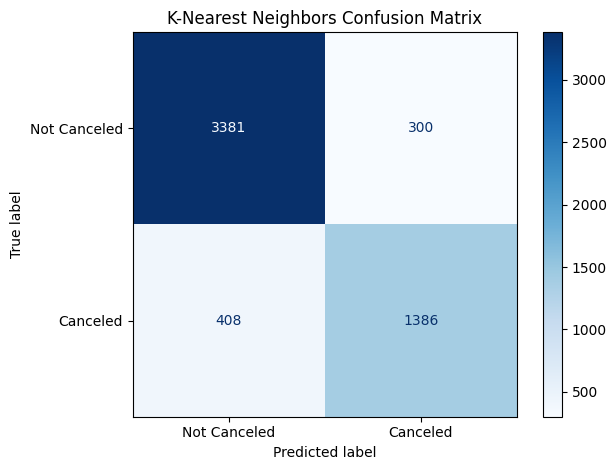


Decision Tree Evaluation

Accuracy : 0.844
Precision: 0.8044
Recall   : 0.6923
F1-Score : 0.7442

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.92      0.89      3681
           1       0.80      0.69      0.74      1794

    accuracy                           0.84      5475
   macro avg       0.83      0.81      0.82      5475
weighted avg       0.84      0.84      0.84      5475



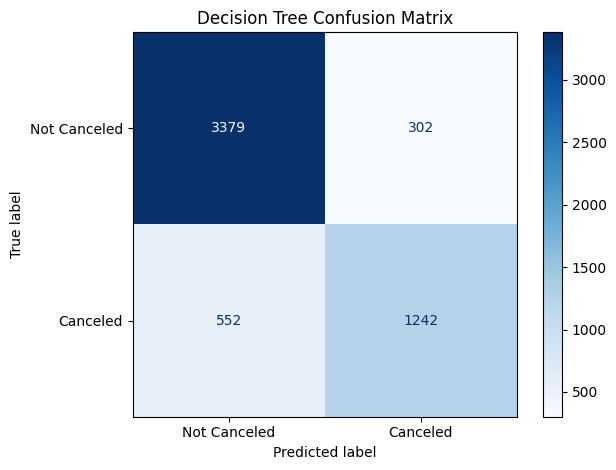


Logistic Regression Evaluation

Accuracy : 0.8429
Precision: 0.7415
Recall   : 0.7993
F1-Score : 0.7693

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.86      0.88      3681
           1       0.74      0.80      0.77      1794

    accuracy                           0.84      5475
   macro avg       0.82      0.83      0.83      5475
weighted avg       0.85      0.84      0.84      5475



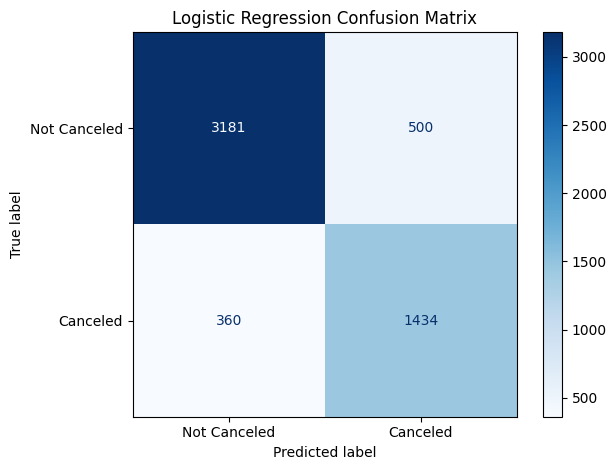

c:\Users\aldie\Downloads\KagglePushRank\IF3170_G12_YuzukiAkatsukiMilikKita\src\algorithms\svm.py:141: RuntimeWarning: SMO berhenti di max_iter=10000 sebelum konvergen
  warnings.warn(



Support Vector Machine Evaluation

Accuracy : 0.8345
Precision: 0.7876
Recall   : 0.6778
F1-Score : 0.7286

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.91      0.88      3681
           1       0.79      0.68      0.73      1794

    accuracy                           0.83      5475
   macro avg       0.82      0.79      0.80      5475
weighted avg       0.83      0.83      0.83      5475



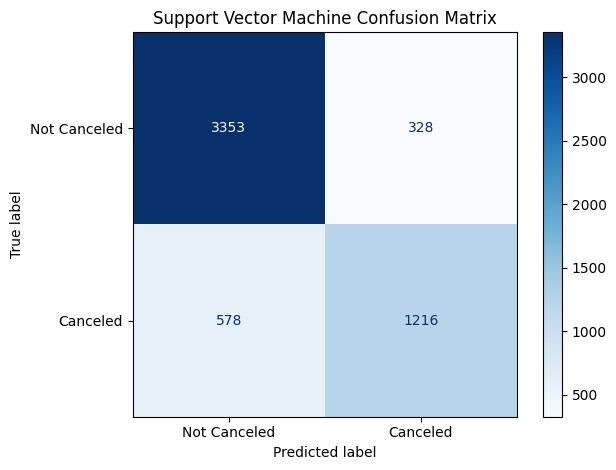

C:\Users\aldie\AppData\Roaming\Python\Python313\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 0 are removed. Consider decreasing the number of bins.
  warnings.warn(
C:\Users\aldie\AppData\Roaming\Python\Python313\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 1 are removed. Consider decreasing the number of bins.
  warnings.warn(
C:\Users\aldie\AppData\Roaming\Python\Python313\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 2 are removed. Consider decreasing the number of bins.
  warnings.warn(
C:\Users\aldie\AppData\Roaming\Python\Python313\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 3 are removed. Consider decreasing the number of bins.
  warnings.wa


Naive Bayes Evaluation

Accuracy : 0.7721
Precision: 0.6757
Recall   : 0.5853
F1-Score : 0.6272

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.86      0.84      3681
           1       0.68      0.59      0.63      1794

    accuracy                           0.77      5475
   macro avg       0.74      0.72      0.73      5475
weighted avg       0.77      0.77      0.77      5475



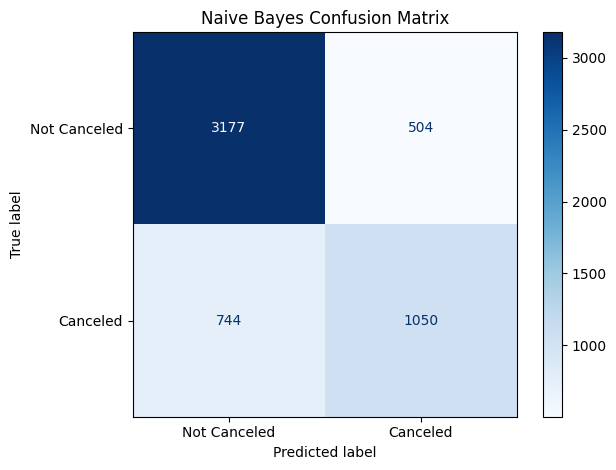

In [38]:
# ==========================================
# MODEL Statistics using from scratch code
# ==========================================
knn_modeling(k=21)
model_evaluation(y_val, y_pred_knn, "K-Nearest Neighbors")

decision_tree_modeling("entropy", max_depth=10)
model_evaluation(y_val, y_pred_dt, "Decision Tree")

logistic_regression_modeling()
model_evaluation(y_val, y_pred_lr, "Logistic Regression")

svm_modeling("rbf", C=1.0)
model_evaluation(y_val, y_pred_svm, "Support Vector Machine")

naive_bayes_modeling()
model_evaluation(y_val, y_pred_nb, "Naive Bayes")

## Improvements

This part covers hyperparameter tuning, cross-validation, and further visualization.

In [39]:
# ==========================================
# Hyperparameter Tuning KNN + bobot feature
# ==========================================

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

param_grid = {
    "group_1": [1.0],
    "group_2": [1.5, 2.0, 2.5],
    "group_3": [0.5, 0.75, 1.0, 1.25],
    "group_4": [1.0, 1.5, 2.0, 2.5],
    "k": [21]
}

results = []
for params in ParameterGrid(param_grid):
    weights = {
        "group_1": params["group_1"],
        "group_2": params["group_2"],
        "group_3": params["group_3"],
        "group_4": params["group_4"]

        # "group_1": params["group_1"],
        # "group_2": params["group_2"],
        # "group_3": params["group_3"],
        # "group_4": params["group_4"],
        # "group_5": params["group_5"],
        # "group_6": params["group_6"]
    }

    fold_scores = []
    for train_idx, val_idx in cv.split(X, y):
        pipeline = knn_pipeline()

        pipeline.set_params(column_transformer__transformer_weights=weights)

        X_train_prepared = pipeline.fit_transform(X.iloc[train_idx])
        X_val_prepared = pipeline.transform(X.iloc[val_idx])

        model = KNeighborsClassifier(n_neighbors=params["k"], metric="manhattan", weights="distance", algorithm="brute", n_jobs=-1)
        model.fit(X_train_prepared, y.iloc[train_idx])

        predictions = model.predict(X_val_prepared)
        fold_scores.append(accuracy_score(y.iloc[val_idx], predictions))

    results.append({
        **params,
        "accuracy": np.mean(fold_scores),
        "std": np.std(fold_scores)
    })

    print(params, "accuracy:", round(np.mean(fold_scores), 6))

tuning_result = (pd.DataFrame(results).sort_values(["accuracy", "std"], ascending=[False, True]).reset_index(drop=True))
display(tuning_result.head(10))

{'group_1': 1.0, 'group_2': 1.5, 'group_3': 0.5, 'group_4': 1.0, 'k': 21} accuracy: 0.866547
{'group_1': 1.0, 'group_2': 1.5, 'group_3': 0.5, 'group_4': 1.5, 'k': 21} accuracy: 0.867205
{'group_1': 1.0, 'group_2': 1.5, 'group_3': 0.5, 'group_4': 2.0, 'k': 21} accuracy: 0.867789
{'group_1': 1.0, 'group_2': 1.5, 'group_3': 0.5, 'group_4': 2.5, 'k': 21} accuracy: 0.86768
{'group_1': 1.0, 'group_2': 1.5, 'group_3': 0.75, 'group_4': 1.0, 'k': 21} accuracy: 0.865378
{'group_1': 1.0, 'group_2': 1.5, 'group_3': 0.75, 'group_4': 1.5, 'k': 21} accuracy: 0.86578
{'group_1': 1.0, 'group_2': 1.5, 'group_3': 0.75, 'group_4': 2.0, 'k': 21} accuracy: 0.866474
{'group_1': 1.0, 'group_2': 1.5, 'group_3': 0.75, 'group_4': 2.5, 'k': 21} accuracy: 0.866401
{'group_1': 1.0, 'group_2': 1.5, 'group_3': 1.0, 'group_4': 1.0, 'k': 21} accuracy: 0.865232
{'group_1': 1.0, 'group_2': 1.5, 'group_3': 1.0, 'group_4': 1.5, 'k': 21} accuracy: 0.865743
{'group_1': 1.0, 'group_2': 1.5, 'group_3': 1.0, 'group_4': 2.0, 'k'

,group_1,group_2,group_3,group_4,k,accuracy,std
0,1.0,2.5,0.50,2.5,21,0.869324,0.002886
1,1.0,2.5,0.50,2.0,21,0.869068,0.002991
2,1.0,2.5,0.50,1.5,21,0.868849,0.002806
3,1.0,2.0,0.50,2.5,21,0.868264,0.002971
4,1.0,2.0,0.50,2.0,21,0.868081,0.002939
5,1.0,2.0,0.75,2.5,21,0.868008,0.002414
6,1.0,2.5,0.75,2.5,21,0.868008,0.002903
7,1.0,2.5,0.50,1.0,21,0.867899,0.003052
8,1.0,2.0,0.75,2.0,21,0.867826,0.002425
9,1.0,2.5,0.75,2.0,21,0.867789,0.002999


Pada proses hyperparameter tuning ini, parameter yang diuji adalah bobot setiap kelompok fitur. Bobot group_2 diuji pada nilai 1.5, 2.0, dan 2.5, group_3 pada 0.5, 0.75, 1.0, dan 1.25, serta group_4 pada 1.0, 1.5, 2.0, dan 2.5. Bobot group_1 tetap 1.0 sebagai acuan. Seluruh 48 kombinasi bobot diuji menggunakan 5-fold Stratified Cross-Validation agar proporsi kelas pada setiap fold tetap seimbang, kemudian dipilih kombinasi dengan rata-rata akurasi tertinggi.

### Logistic Regression

Tuning memakai fungsi `tune` dari `src/tuning.py` (5-fold Stratified CV pada data latih, macro F1 pada *threshold* 0,5). Grid berisi konfigurasi terbaik dari eksperimen yang lebih besar di `src/run_logistic_regression.py`: SGA dengan L2, L1, dan Elastic Net, serta AdaGrad dengan L2 dan L1. Kolom `bobot_nol` menghitung bobot yang tepat nol setelah training.

In [40]:
# ==========================================
# Hyperparameter Tuning Logistic Regression
# ==========================================
from src.tuning import tune

logistic_regression_modeling()
lr_results = pd.concat([tune(ScratchLogisticRegression(random_state=42), grid, x_train_lr, y_train, random_state=42, verbose=False) for grid in GRIDS])
lr_results = lr_results.sort_values("kfold_mean", ascending=False, ignore_index=True)

# Menghitung bobot yang tepat nol buat ngeliat efek L1 dan Elastic Net.
zero_weights = []
for params in lr_results["params"]:
    model = ScratchLogisticRegression(random_state=42, **params).fit(x_train_lr, y_train)
    zero_weights.append(int(np.sum(model.weights[1:] == 0)))
lr_results["bobot_nol"] = zero_weights

pd.set_option("display.max_colwidth", None)
display(lr_results[["params", "kfold_mean", "kfold_std", "bobot_nol"]].round(4))

,params,kfold_mean,kfold_std,bobot_nol
0,"{'optimizer': 'adagrad', 'n_epochs': 5, 'learning_rate': 0.05, 'penalty': 'l1', 'reg_lambda': 0.0001}",0.8193,0.0028,328
1,"{'optimizer': 'adagrad', 'n_epochs': 5, 'learning_rate': 0.05, 'penalty': 'l2', 'reg_lambda': 0.0003}",0.8191,0.0026,5
2,"{'optimizer': 'sga', 'n_epochs': 10, 'learning_rate': 0.01, 'lr_decay': 0.7, 'penalty': 'l1', 'reg_lambda': 0.0001}",0.8171,0.0017,344
3,"{'optimizer': 'sga', 'n_epochs': 10, 'learning_rate': 0.01, 'lr_decay': 0.7, 'penalty': 'elasticnet', 'reg_lambda': 0.0003, 'l1_ratio': 0.2}",0.8169,0.0021,278
4,"{'optimizer': 'sga', 'n_epochs': 10, 'learning_rate': 0.01, 'lr_decay': 0.7, 'penalty': 'l2', 'reg_lambda': 0.0003}",0.8165,0.0025,5


Kelima konfigurasi berada di rentang 0,8165 sampai 0,8193. Selisih terbesarnya 0,003, hampir sama dengan *std* antar *fold* (sekitar 0,002 sampai 0,003), sehingga pilihan *optimizer* dan penalti tidak banyak berpengaruh. Pada pembagian data ini AdaGrad L1 unggul tipis, sedangkan pada runner (pembagian *fold* berbeda) SGA L2 yang unggul. Karena keduanya setara, notebook memakai SGA L2 agar sama dengan runner dan berkas submission.

L1 dan Elastic Net membuat ratusan bobot tepat nol (328 sampai 344 untuk L1, 278 untuk Elastic Net), sedangkan L2 hanya 5 bobot nol, yaitu kolom yang tidak pernah aktif di data latih. Bobot yang dinolkan adalah interaksi langka, dan skornya hampir tidak berubah karena fitur interaksi saling berkorelasi.

SGA (10 epoch, 18.0 detik): training loss akhir = 0.3210
AdaGrad (5 epoch, 10.6 detik): training loss akhir = 0.3259


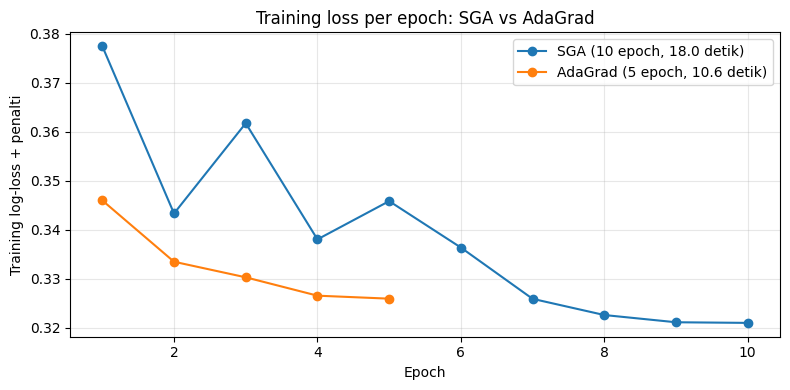

In [41]:
# ==========================================
# Konvergensi SGA vs AdaGrad
# ==========================================
plt.figure(figsize=(8, 4))
for optimizer in ["sga", "adagrad"]:
    grid = next(g for g in GRIDS if g["optimizer"] == [optimizer] and g["penalty"] == ["l2"])
    params = {key: values[0] for key, values in grid.items()}

    start = time.time()
    model = ScratchLogisticRegression(random_state=42, **params).fit(x_train_lr, y_train)
    elapsed = time.time() - start

    label = f"{optimizer.upper() if optimizer == 'sga' else 'AdaGrad'} ({params['n_epochs']} epoch, {elapsed:.1f} detik)"
    plt.plot(range(1, len(model.loss_history) + 1), model.loss_history, marker="o", label=label)
    print(f"{label}: training loss akhir = {model.loss_history[-1]:.4f}")

plt.xlabel("Epoch")
plt.ylabel("Training log-loss + penalti")
plt.title("Training loss per epoch: SGA vs AdaGrad")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Bonus algoritma optimasi: AdaGrad.** SGA pada salindia memakai *learning rate* yang sama untuk semua bobot. AdaGrad (Duchi, Hazan, dan Singer, 2011, *Journal of Machine Learning Research* 12) membagi *learning rate* setiap bobot dengan akar jumlah kuadrat gradien historisnya, η/√(Σg²). Kolom interaksi yang jarang aktif jarang menerima gradien, sehingga bobotnya mendapat langkah besar saat kolomnya aktif, sedangkan bobot kolom yang sering aktif mendapat langkah kecil. Langkahnya juga mengecil sendiri, sehingga tidak perlu `lr_decay`.

Pada grafik di atas, AdaGrad dengan 5 *epoch* mencapai *training loss* yang mendekati SGA dengan 10 *epoch* (0,3259 dibanding 0,3210) dalam waktu yang lebih singkat, sementara macro F1 keduanya setara pada tabel tuning. Angka waktu bisa sedikit berbeda di setiap mesin.

In [42]:
# ==========================================
# Bonus: Video Kontur Log-loss
# ==========================================
from IPython.display import Video

# Video dibuat oleh src/bonus_logistic_regression_video.py, jalankan script itu dulu kalau filenya belum ada.
Video(str(CFG.OUTPUT_DIR / "logistic_regression_contour.mp4"), embed=True, width=800)

**Bonus video.** Video menampilkan kontur *log-loss* model satu fitur (`days_before_arrival` yang distandardisasi) pada bidang θ₀ dan θ₁, bersama lintasan SGA dari (0, 0) menuju titik minimum (bintang merah). Lintasannya bergerigi karena setiap *update* hanya memakai satu baris data. Di akhir training θ₀ = −0,787 dan θ₁ = 0,988 dengan *log-loss* 0,5394, berimpit dengan minimum pada grid.

---

# Comparison with scikit-learn <a name="8"></a>

---

This section compares each from-scratch model with its `scikit-learn` counterpart.

In [43]:
# ==========================================
# Comparision with scikit learn
# ==========================================
def compare_with_sklearn(model_name, scratch_predictions, sklearn_model, X_train_model, X_val_model):
    sklearn_model.fit(X_train_model, y_train)
    sklearn_predictions = sklearn_model.predict(X_val_model)

    model_evaluation(y_val, scratch_predictions, f"{model_name} - From Scratch")
    model_evaluation(y_val, sklearn_predictions, f"{model_name} - Scikit-learn")


KNN - From Scratch Evaluation

Accuracy : 0.8707
Precision: 0.8221
Recall   : 0.7726
F1-Score : 0.7966

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.92      0.91      3681
           1       0.82      0.77      0.80      1794

    accuracy                           0.87      5475
   macro avg       0.86      0.85      0.85      5475
weighted avg       0.87      0.87      0.87      5475



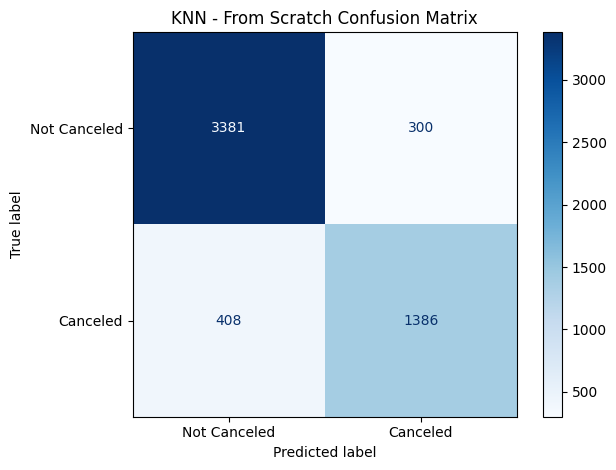


KNN - Scikit-learn Evaluation

Accuracy : 0.8707
Precision: 0.8221
Recall   : 0.7726
F1-Score : 0.7966

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.92      0.91      3681
           1       0.82      0.77      0.80      1794

    accuracy                           0.87      5475
   macro avg       0.86      0.85      0.85      5475
weighted avg       0.87      0.87      0.87      5475



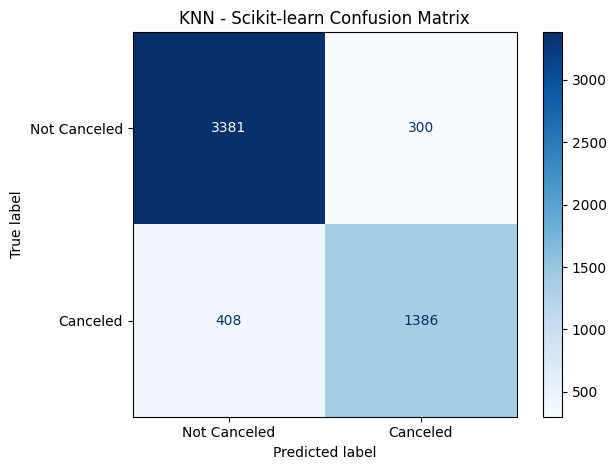

In [44]:
# ==========================================
# Compare KNN
# ==========================================
knn_modeling(k=21)
compare_with_sklearn("KNN", y_pred_knn, KNeighborsClassifier(n_neighbors=21, metric="manhattan", weights="distance", algorithm="brute", n_jobs=-1), x_train_prepared, x_val_prepared)


Decision Tree - From Scratch Evaluation

Accuracy : 0.844
Precision: 0.8044
Recall   : 0.6923
F1-Score : 0.7442

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.92      0.89      3681
           1       0.80      0.69      0.74      1794

    accuracy                           0.84      5475
   macro avg       0.83      0.81      0.82      5475
weighted avg       0.84      0.84      0.84      5475



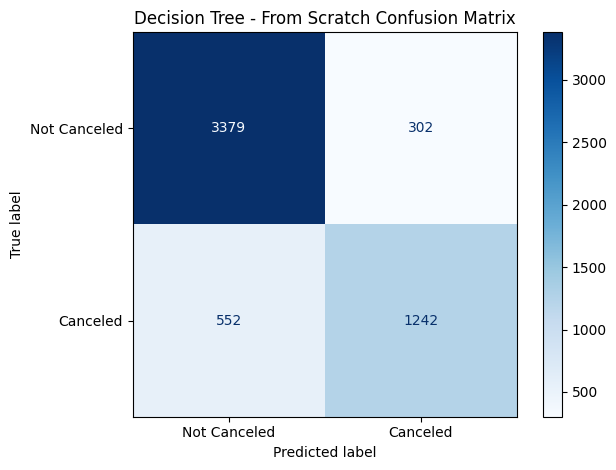


Decision Tree - Scikit-learn Evaluation

Accuracy : 0.8517
Precision: 0.802
Recall   : 0.7269
F1-Score : 0.7626

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.91      0.89      3681
           1       0.80      0.73      0.76      1794

    accuracy                           0.85      5475
   macro avg       0.84      0.82      0.83      5475
weighted avg       0.85      0.85      0.85      5475



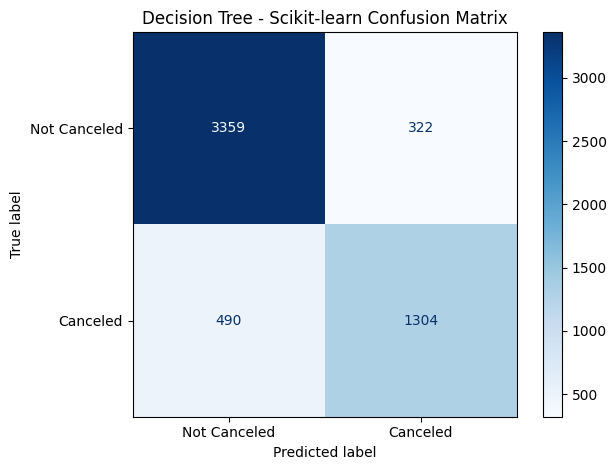

In [45]:
# ==========================================
# Compare DTL
# ==========================================
decision_tree_modeling(criterion="entropy", max_depth=10)
compare_with_sklearn("Decision Tree", y_pred_dt, DecisionTreeClassifier(criterion="entropy", max_depth=10, random_state=42), x_train_prepared, x_val_prepared)


Logistic Regression - From Scratch Evaluation

Accuracy : 0.8429
Precision: 0.7415
Recall   : 0.7993
F1-Score : 0.7693

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.86      0.88      3681
           1       0.74      0.80      0.77      1794

    accuracy                           0.84      5475
   macro avg       0.82      0.83      0.83      5475
weighted avg       0.85      0.84      0.84      5475



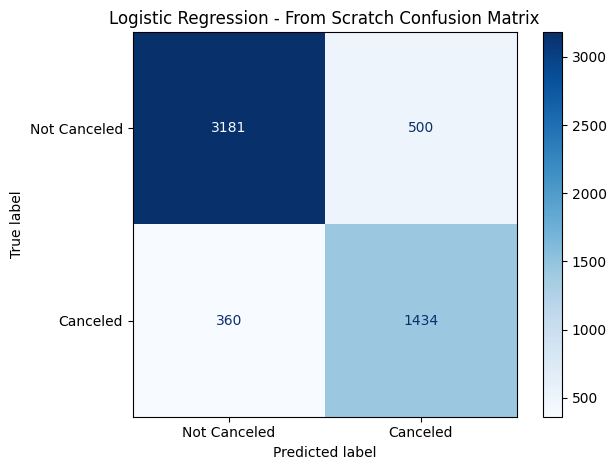


Logistic Regression - Scikit-learn Evaluation

Accuracy : 0.8396
Precision: 0.74
Recall   : 0.7871
F1-Score : 0.7628

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.87      0.88      3681
           1       0.74      0.79      0.76      1794

    accuracy                           0.84      5475
   macro avg       0.82      0.83      0.82      5475
weighted avg       0.84      0.84      0.84      5475



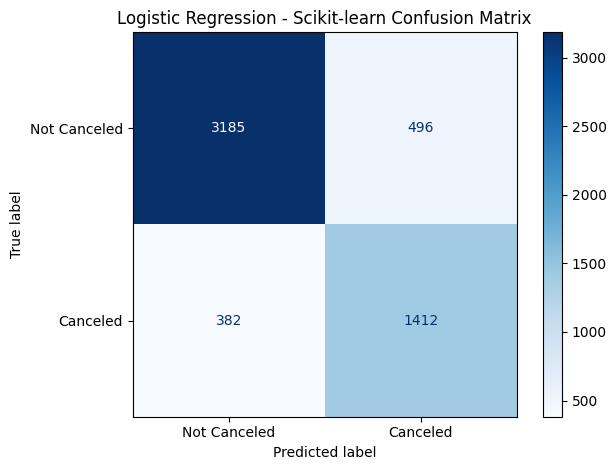

Threshold           : 0.4
Macro F1 from scratch: 0.8251
Macro F1 scikit-learn: 0.8208
Prediksi yang sama  : 96.6%


In [46]:
# ==========================================
# Compare Logistic Regression
# ==========================================
logistic_regression_modeling()

# Menyamakan C sklearn dengan reg_lambda dan memakai threshold yang sama biar perbandingannya adil.
sklearn_lr = make_sklearn_model(LR_PARAMS, len(y_train)).fit(x_train_lr, y_train)
y_pred_lr_sklearn = (sklearn_lr.predict_proba(x_val_lr)[:, 1] >= lr_threshold).astype(int)

model_evaluation(y_val, y_pred_lr, "Logistic Regression - From Scratch")
model_evaluation(y_val, y_pred_lr_sklearn, "Logistic Regression - Scikit-learn")

print("Threshold           :", lr_threshold)
print("Macro F1 from scratch:", round(macro_f1_score(y_val, y_pred_lr), 4))
print("Macro F1 scikit-learn:", round(macro_f1_score(y_val, y_pred_lr_sklearn), 4))
print(f"Prediksi yang sama  : {np.mean(y_pred_lr == y_pred_lr_sklearn):.1%}")

Dengan C = 1/(λ·n) yang setara dan *threshold* yang sama (0,40), implementasi sendiri mendapat macro F1 0,8251 dan scikit-learn 0,8210, dengan 96,7% prediksi sama. Sisa perbedaan berasal dari cara optimasi: SGA berhenti setelah 10 *epoch*, sedangkan lbfgs pada scikit-learn mengoptimasi sampai konvergen.

c:\Users\aldie\Downloads\KagglePushRank\IF3170_G12_YuzukiAkatsukiMilikKita\src\algorithms\svm.py:141: RuntimeWarning: SMO berhenti di max_iter=10000 sebelum konvergen
  warnings.warn(
C:\Users\aldie\AppData\Roaming\Python\Python313\site-packages\sklearn\svm\_base.py:337: ConvergenceWarning: Solver terminated early (max_iter=2000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(



SVM - From Scratch Evaluation

Accuracy : 0.7931
Precision: 0.7509
Recall   : 0.5513
F1-Score : 0.6358

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.91      0.86      3681
           1       0.75      0.55      0.64      1794

    accuracy                           0.79      5475
   macro avg       0.78      0.73      0.75      5475
weighted avg       0.79      0.79      0.78      5475



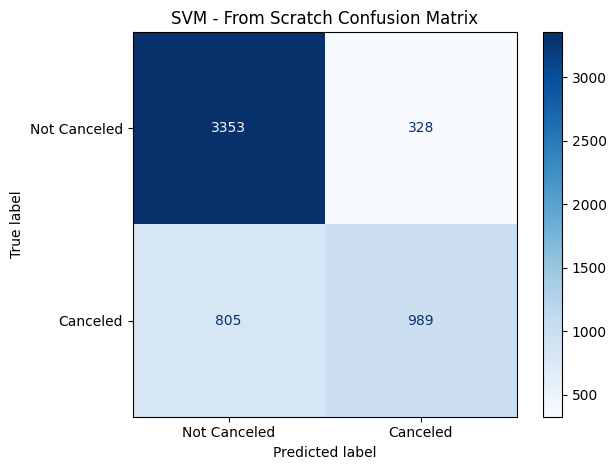


SVM - Scikit-learn Evaluation

Accuracy : 0.4026
Precision: 0.337
Recall   : 0.8512
F1-Score : 0.4828

Classification Report:
              precision    recall  f1-score   support

           0       0.72      0.18      0.29      3681
           1       0.34      0.85      0.48      1794

    accuracy                           0.40      5475
   macro avg       0.53      0.52      0.39      5475
weighted avg       0.59      0.40      0.36      5475



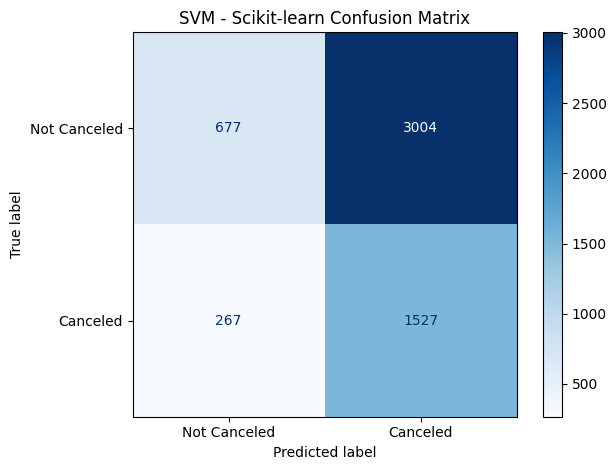

In [47]:
# ==========================================
# Compare SVM
# ==========================================
svm_modeling(kernel="linear", C=1.0)
compare_with_sklearn("SVM", y_pred_svm, SVC(kernel="linear", C=1.0, max_iter=2000), x_train_prepared, x_val_prepared)

C:\Users\aldie\AppData\Roaming\Python\Python313\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 0 are removed. Consider decreasing the number of bins.
  warnings.warn(
C:\Users\aldie\AppData\Roaming\Python\Python313\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 1 are removed. Consider decreasing the number of bins.
  warnings.warn(
C:\Users\aldie\AppData\Roaming\Python\Python313\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 2 are removed. Consider decreasing the number of bins.
  warnings.warn(
C:\Users\aldie\AppData\Roaming\Python\Python313\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 3 are removed. Consider decreasing the number of bins.
  warnings.wa


Naive Bayes - From Scratch Evaluation

Accuracy : 0.7721
Precision: 0.6757
Recall   : 0.5853
F1-Score : 0.6272

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.86      0.84      3681
           1       0.68      0.59      0.63      1794

    accuracy                           0.77      5475
   macro avg       0.74      0.72      0.73      5475
weighted avg       0.77      0.77      0.77      5475



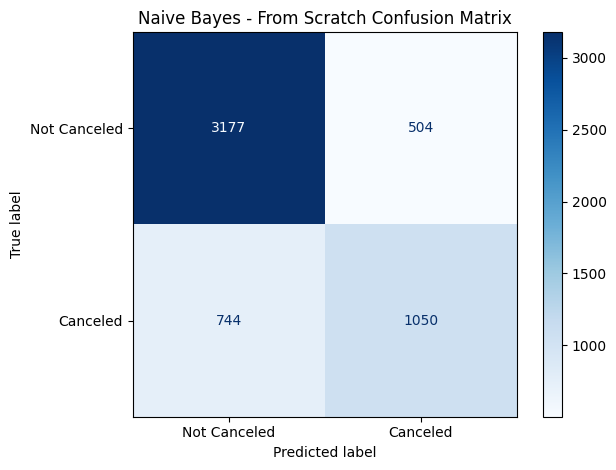


Naive Bayes - Scikit-learn Evaluation

Accuracy : 0.7721
Precision: 0.6757
Recall   : 0.5853
F1-Score : 0.6272

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.86      0.84      3681
           1       0.68      0.59      0.63      1794

    accuracy                           0.77      5475
   macro avg       0.74      0.72      0.73      5475
weighted avg       0.77      0.77      0.77      5475



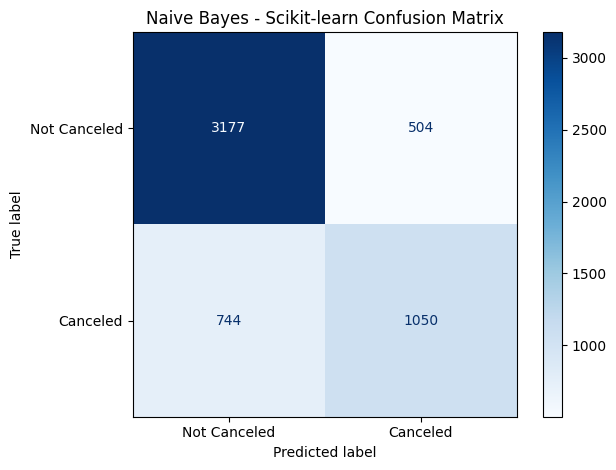

In [48]:
# ==========================================
# Compare Naive Bayes
# ==========================================
naive_bayes_modeling(alpha=1.0)

x_train_nb = naive_bayes_preprocessor.transform(x_train).astype(int)
x_val_nb = naive_bayes_preprocessor.transform(x_val).astype(int)

compare_with_sklearn("Naive Bayes", y_pred_nb, CategoricalNB(alpha=1.0), x_train_nb, x_val_nb)

---

# Saving and Loading Models <a name="9"></a>

---

This section stores the trained models and restores them for prediction.

In [49]:
# ==========================================
# Saving adn Loading Models
# ==========================================
final_preparation_pipeline = knn_pipeline()
x_full_prepared = final_preparation_pipeline.fit_transform(X)

final_knn = KNN(k=21)
final_knn.fit(x_full_prepared, y)

model_artifact = {
    "preparation_pipeline": final_preparation_pipeline,
    "model": final_knn
}

model_path = CFG.OUTPUT_DIR / "knn_model.pkl"
save_model(model_artifact, model_path)

loaded_artifact = load_model(model_path)
loaded_pipeline = loaded_artifact["preparation_pipeline"]
loaded_model = loaded_artifact["model"]

print(f"Model saved and loaded from {model_path}")

Model saved and loaded from c:\Users\aldie\Downloads\KagglePushRank\IF3170_G12_YuzukiAkatsukiMilikKita\output\knn_model.pkl


In [50]:
# ==========================================
# Saving and Loading Logistic Regression
# ==========================================
logistic_regression_modeling()

# Melatih ulang pipeline dan model di seluruh train.csv, threshold ikut disimpan soalnya bagian dari keputusan model.
final_lr_pipeline = build_logistic_regression_pipeline()
x_full_lr = final_lr_pipeline.fit_transform(X)
final_lr = ScratchLogisticRegression(random_state=42, **LR_PARAMS).fit(x_full_lr, y)

lr_artifact = {"preparation_pipeline": final_lr_pipeline, "model": final_lr, "threshold": lr_threshold}
lr_model_path = CFG.OUTPUT_DIR / "logistic_regression_model.pkl"
save_model(lr_artifact, lr_model_path)

loaded_lr = load_model(lr_model_path)
x_test_lr = loaded_lr["preparation_pipeline"].transform(x_test)
lr_test_pred = loaded_lr["model"].predict(x_test_lr, threshold=loaded_lr["threshold"])

assert (lr_test_pred == final_lr.predict(final_lr_pipeline.transform(x_test), threshold=lr_threshold)).all()
print(f"Model saved and loaded from output/{lr_model_path.name}")
print("Prediksi test dari model hasil load sama persis dengan model sebelum disimpan.")

Model saved and loaded from output/logistic_regression_model.pkl
Prediksi test dari model hasil load sama persis dengan model sebelum disimpan.


Artefak Logistic Regression berisi pipeline preprocessing, model, dan *threshold*, karena ketiganya dibutuhkan untuk menghasilkan prediksi yang sama. Pipeline dan model dilatih ulang di seluruh `train.csv` sebelum disimpan, lalu prediksi test dari model hasil *load* dicek sama persis dengan model sebelum disimpan.

---

# Kaggle Submission <a name="10"></a>

---

The final pipeline and model are fitted on the original training set, and the test set is only transformed. The submission file contains the `id` and `is_canceled` columns.

In [51]:
def submit(model, X, y, X_test, fit_model=True):
    if fit_model:
        model.fit(X, y)

    predictions = np.array([model.predict(row) for row in X_test], dtype=int)

    result = pd.read_csv(CFG.DATA_DIR / "sample_submission.csv", dtype={"id": str})
    result["is_canceled"] = predictions

    path = CFG.OUTPUT_DIR / "submission.csv"
    result.to_csv(path, index=False)

    print(f"{len(result)} rows written to {path}")
    display(result.head())

    return result

In [52]:
x_test_loaded = loaded_pipeline.transform(x_test)
submission = submit(loaded_model, None, None, x_test_loaded, fit_model=False)

6844 rows written to c:\Users\aldie\Downloads\KagglePushRank\IF3170_G12_YuzukiAkatsukiMilikKita\output\submission.csv


,id,is_canceled
0,5cb6f473,1
1,c06b4ab3,1
2,22bf3fc3,0
3,25408a48,0
4,621586b6,0


---

# Error Analysis <a name="11"></a>

---

The analysis supports each step taken in this notebook.

Analisis kesalahan dilakukan pada model final yang dipakai untuk submission, yaitu KNN berbobot dengan k = 21, menggunakan hasil prediksi pada data validasi (`y_pred_knn`). Setiap prediksi dikelompokkan menjadi True Positive (TP), True Negative (TN), False Positive (FP), dan False Negative (FN), lalu kesalahan dianalisis berdasarkan segmen data, karakteristik fitur, missing value, dan tingkat keyakinan tetangga.

In [53]:
# ==========================================
# ERROR ANALYSIS: JENIS KESALAHAN
# ==========================================

# Menggunakan prediksi KNN final pada data validasi
if "y_pred_knn" not in globals():
    knn_modeling(k=21)

error_df = x_val.copy()
error_df["actual"] = y_val.to_numpy()
error_df["predicted"] = y_pred_knn

error_df["error_type"] = np.select(
    [
        (error_df["actual"] == 1) & (error_df["predicted"] == 1),
        (error_df["actual"] == 0) & (error_df["predicted"] == 0),
        (error_df["actual"] == 0) & (error_df["predicted"] == 1),
    ],
    ["TP", "TN", "FP"],
    default="FN",
)
error_df["salah"] = error_df["actual"] != error_df["predicted"]
error_df["fn"] = error_df["error_type"] == "FN"
error_df["fp"] = error_df["error_type"] == "FP"

print("\n=============================================")
print("Ringkasan Jenis Prediksi")
print("=============================================\n")

summary = error_df["error_type"].value_counts().reindex(["TP", "TN", "FP", "FN"]).to_frame("jumlah")
summary["persentase (%)"] = (summary["jumlah"] / len(error_df) * 100).round(2)
display(summary)

total_batal = (error_df["actual"] == 1).sum()
total_tidak_batal = (error_df["actual"] == 0).sum()

print("Total prediksi salah        :", error_df["salah"].sum(), "dari", len(error_df))
print("Batal yang tidak terdeteksi :", f"{error_df['fn'].sum() / total_batal:.2%}", "(FN dibagi seluruh reservasi batal)")
print("Tidak batal yang dianggap batal:", f"{error_df['fp'].sum() / total_tidak_batal:.2%}", "(FP dibagi seluruh reservasi tidak batal)")


Ringkasan Jenis Prediksi



,jumlah,persentase (%)
error_type,,
TP,1386,25.32
TN,3381,61.75
FP,300,5.48
FN,408,7.45


Total prediksi salah        : 708 dari 5475
Batal yang tidak terdeteksi : 22.74% (FN dibagi seluruh reservasi batal)
Tidak batal yang dianggap batal: 8.15% (FP dibagi seluruh reservasi tidak batal)


In [54]:
# ==========================================
# ERROR ANALYSIS: KESALAHAN PER SEGMEN DATA
# ==========================================

def segment_error(column):
    # Nilai kosong ditampilkan sebagai kelompok "Missing"
    key = error_df[column]
    if isinstance(key.dtype, pd.CategoricalDtype):
        key = key.cat.add_categories("Missing").fillna("Missing")
    else:
        key = key.astype(object).where(key.notna(), "Missing")

    grouped = error_df.groupby(key, observed=True)
    jumlah = grouped.size()
    jumlah_batal = grouped["actual"].sum()

    result = pd.DataFrame({
        "jumlah": jumlah,
        "batal aktual (%)": grouped["actual"].mean() * 100,
        "error rate (%)": grouped["salah"].mean() * 100,
        "FN rate (%)": grouped["fn"].sum() / jumlah_batal.replace(0, np.nan) * 100,
        "FP rate (%)": grouped["fp"].sum() / (jumlah - jumlah_batal).replace(0, np.nan) * 100,
    })
    return result.round(2)

# Kelompok jarak pemesanan dan permintaan khusus
error_df["lead_time_group"] = pd.cut(
    error_df["days_before_arrival"],
    bins=[-1, 7, 30, 90, 180, 450],
    labels=["0-7 hari", "8-30 hari", "31-90 hari", "91-180 hari", ">180 hari"],
)
error_df["special_requests_group"] = (
    error_df["special_requests"].map(lambda value: "Missing" if pd.isna(value) else str(int(min(value, 3))) if value < 3 else "3+")
)

segment_columns = ["lead_time_group", "booking_channel", "special_requests_group", "meal_package", "arrival_year", "is_returning_guest"]

for column in segment_columns:
    print("\n=============================================")
    print(f"Error per {column}")
    print("=============================================\n")
    display(segment_error(column))


Error per lead_time_group



,jumlah,batal aktual (%),error rate (%),FN rate (%),FP rate (%)
lead_time_group,,,,,
0-7 hari,871,8.73,5.97,55.26,1.26
8-30 hari,947,17.74,13.52,54.76,4.62
31-90 hari,1551,26.43,15.28,33.17,8.85
91-180 hari,1124,44.75,18.33,20.08,16.91
>180 hari,768,73.83,7.03,2.65,19.40
Missing,214,32.71,14.49,31.43,6.25



Error per booking_channel



,jumlah,batal aktual (%),error rate (%),FN rate (%),FP rate (%)
booking_channel,,,,,
Airline,21,9.52,19.05,100.00,10.53
Complimentary,53,0.00,0.00,NaN,0.00
Corporate,307,11.40,6.19,51.43,0.37
Offline Agent,1597,30.62,6.89,12.07,4.60
Online Travel Agent,3497,36.26,16.44,25.95,11.04



Error per special_requests_group



,jumlah,batal aktual (%),error rate (%),FN rate (%),FP rate (%)
special_requests_group,,,,,
0,2541,42.90,13.22,14.04,12.61
1,1707,23.90,14.24,47.79,3.70
2,624,14.10,7.37,36.36,2.61
3+,111,0.00,2.70,NaN,2.70
Missing,492,42.28,16.26,13.46,18.31


... (2 outputs left out)


Error per arrival_year



,jumlah,batal aktual (%),error rate (%),FN rate (%),FP rate (%)
arrival_year,,,,,
2023,968,15.08,9.09,39.04,3.77
2024,4507,36.57,13.76,21.30,9.41



Error per is_returning_guest



,jumlah,batal aktual (%),error rate (%),FN rate (%),FP rate (%)
is_returning_guest,,,,,
0,5338,33.59,13.24,22.76,8.43
1,137,0.73,0.73,0.00,0.74


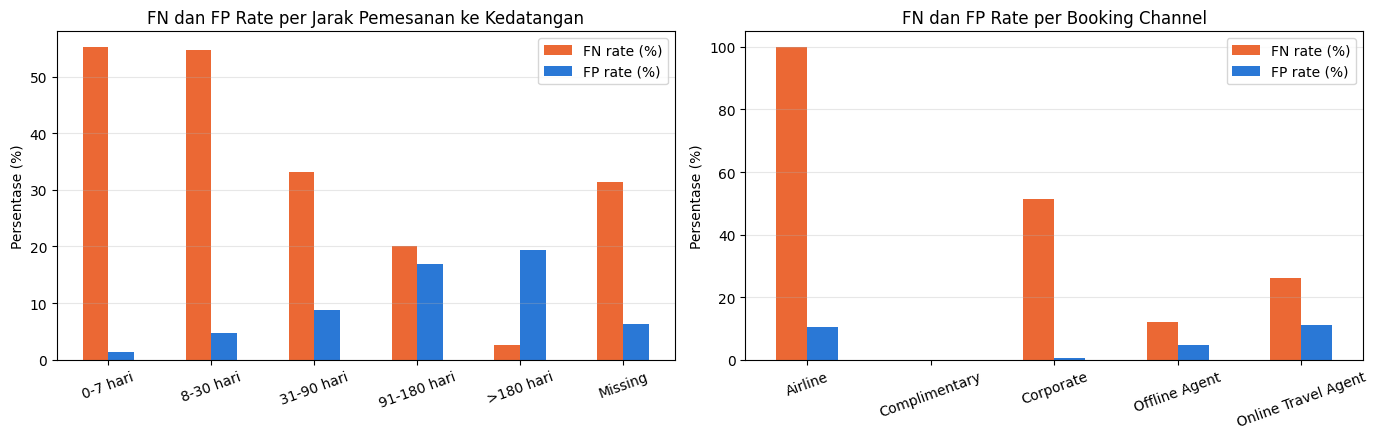

In [55]:
# ==========================================
# ERROR ANALYSIS: VISUALISASI FN DAN FP RATE
# ==========================================

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

for ax, column, title in zip(
    axes,
    ["lead_time_group", "booking_channel"],
    ["Jarak Pemesanan ke Kedatangan", "Booking Channel"],
):
    segment = segment_error(column)[["FN rate (%)", "FP rate (%)"]]
    segment.plot.bar(ax=ax, color=["#eb6834", "#2a78d6"], rot=20)
    ax.set_title(f"FN dan FP Rate per {title}")
    ax.set_xlabel("")
    ax.set_ylabel("Persentase (%)")
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [56]:
# ==========================================
# ERROR ANALYSIS: KARAKTERISTIK FITUR PER JENIS PREDIKSI
# ==========================================

compare_cols = [
    "days_before_arrival",
    "special_requests",
    "nightly_rate_idr",
    "weekday_nights",
    "weekend_nights",
    "num_adults",
    "prior_completed_bookings",
]

print("\n=============================================")
print("Rata-rata Fitur per Jenis Prediksi")
print("=============================================\n")

feature_profile = error_df.groupby("error_type")[compare_cols].mean().reindex(["TP", "FN", "TN", "FP"])
feature_profile["nightly_rate_idr"] = feature_profile["nightly_rate_idr"] / 1e6
feature_profile = feature_profile.rename(columns={"nightly_rate_idr": "nightly_rate (juta Rp)"})
display(feature_profile.round(2))


Rata-rata Fitur per Jenis Prediksi



,days_before_arrival,special_requests,nightly_rate (juta Rp),weekday_nights,weekend_nights,num_adults,prior_completed_bookings
error_type,,,,,,,
TP,162.01,0.27,1.86,2.41,0.87,1.92,0.00
FN,66.12,0.68,1.78,2.22,0.95,1.85,0.00
TN,54.75,0.84,1.65,2.06,0.77,1.80,0.21
FP,101.82,0.34,1.80,2.46,1.03,1.96,0.00


In [57]:
# ==========================================
# ERROR ANALYSIS: PENGARUH MISSING VALUE
# ==========================================

error_df["jumlah_missing"] = x_val.isna().sum(axis=1).clip(upper=2).map({0: "0", 1: "1", 2: "2+"}).to_numpy()

print("\n=============================================")
print("Error berdasarkan Jumlah Missing Value per Baris")
print("=============================================\n")
display(segment_error("jumlah_missing"))


Error berdasarkan Jumlah Missing Value per Baris



,jumlah,batal aktual (%),error rate (%),FN rate (%),FP rate (%)
jumlah_missing,,,,,
0,3361,32.19,13.48,24.58,8.21
1,1652,32.75,12.17,20.70,8.01
2+,462,37.01,11.69,17.54,8.25



Error berdasarkan Keyakinan Tetangga



,jumlah,batal aktual (%),error rate (%),FN rate (%),FP rate (%)
keyakinan,,,,,
"0-0,2 (ragu)",527,45.92,45.35,46.69,44.21
"0,2-0,4",592,44.76,29.73,33.96,26.30
"0,4-0,6",723,39.70,17.70,27.53,11.24
"0,6-0,8",915,29.62,10.60,26.20,4.04
"0,8-1 (yakin)",2718,26.82,2.50,7.54,0.65


Baris dengan keyakinan < 0,4 : 1119 (20.44% data validasi)
Kesalahan pada baris tersebut: 415 dari 708 (58.62% seluruh kesalahan)


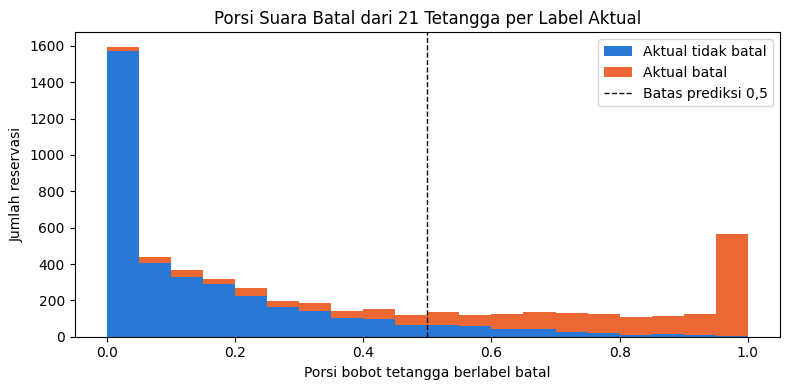

In [58]:
# ==========================================
# ERROR ANALYSIS: KEYAKINAN TETANGGA
# ==========================================

# Porsi bobot (1/jarak) dari tetangga berlabel batal untuk setiap baris validasi.
# Nilai mendekati 0 atau 1 berarti tetangga sepakat, nilai sekitar 0,5 berarti tetangga terbelah.
def cancel_vote_share(model, row):
    model.predict(row)
    distances = np.array([neighbor[0] for neighbor in model.d], dtype=float)
    labels = np.array([neighbor[1] for neighbor in model.d], dtype=float)

    if np.any(distances == 0):
        return labels[distances == 0].mean()

    weights = 1 / distances
    return (weights * labels).sum() / weights.sum()

error_df["cancel_vote_share"] = [cancel_vote_share(knn_model, row) for row in x_val_prepared]
error_df["keyakinan"] = pd.cut(
    (error_df["cancel_vote_share"] - 0.5).abs() * 2,
    bins=[-0.01, 0.2, 0.4, 0.6, 0.8, 1.0],
    labels=["0-0,2 (ragu)", "0,2-0,4", "0,4-0,6", "0,6-0,8", "0,8-1 (yakin)"],
)

print("\n=============================================")
print("Error berdasarkan Keyakinan Tetangga")
print("=============================================\n")
display(segment_error("keyakinan"))

ragu = error_df["keyakinan"].isin(["0-0,2 (ragu)", "0,2-0,4"])
print(f"Baris dengan keyakinan < 0,4 : {ragu.sum()} ({ragu.mean():.2%} data validasi)")
print(f"Kesalahan pada baris tersebut: {error_df.loc[ragu, 'salah'].sum()} dari {error_df['salah'].sum()} ({error_df.loc[ragu, 'salah'].sum() / error_df['salah'].sum():.2%} seluruh kesalahan)")

fig, ax = plt.subplots(figsize=(8, 4))
share_by_class = [
    error_df.loc[error_df["actual"] == 0, "cancel_vote_share"],
    error_df.loc[error_df["actual"] == 1, "cancel_vote_share"],
]
ax.hist(share_by_class, bins=20, range=(0, 1), stacked=True, color=["#2a78d6", "#eb6834"],
        label=["Aktual tidak batal", "Aktual batal"])

# Di kiri garis diprediksi tidak batal, di kanan garis diprediksi batal
ax.axvline(0.5, color="#0b0b0b", linestyle="--", linewidth=1, label="Batas prediksi 0,5")
ax.set_title("Porsi Suara Batal dari 21 Tetangga per Label Aktual")
ax.set_xlabel("Porsi bobot tetangga berlabel batal")
ax.set_ylabel("Jumlah reservasi")
ax.legend()
plt.tight_layout()
plt.show()

### Insights

- Dari 5.475 data validasi, model salah memprediksi 708 baris (12,93%). Kesalahan didominasi False Negative (408 baris) dibanding False Positive (300 baris). Model melewatkan 22,74% reservasi yang sebenarnya batal, sedangkan hanya 8,15% reservasi tidak batal yang salah dianggap batal. Hal ini wajar karena kelas batal adalah kelas minoritas, sehingga tetangga terdekat lebih sering didominasi reservasi tidak batal.
- Kesalahan sangat dipengaruhi `days_before_arrival`, fitur dengan bobot terbesar (2,5) pada pipeline. Untuk pemesanan 0–30 hari sebelum kedatangan, lebih dari 54% pembatalan tidak terdeteksi karena hampir semua tetangganya tidak batal. Sebaliknya, untuk pemesanan di atas 90 hari, FP rate naik menjadi 16,91–19,40% karena model menganggap pemesanan jauh hari cenderung batal. Error rate tertinggi ada pada kelompok 91–180 hari (18,33%), yaitu kelompok dengan proporsi batal paling seimbang (44,75%).
- Berdasarkan channel, Online Travel Agent memiliki error rate tertinggi (16,44%) dengan FN rate 25,95% dan FP rate 11,04%, sedangkan Offline Agent hanya 6,89%. Pada Corporate, lebih dari separuh pembatalan tidak terdeteksi (51,43%) karena pembatalan di channel ini jarang. Seluruh pembatalan melalui Airline juga terlewat, tetapi jumlah datanya hanya 21 baris.
- Reservasi dengan satu permintaan khusus memiliki FN rate 47,79%, sedangkan reservasi dengan `special_requests` kosong memiliki FP rate tertinggi (18,31%). Nilai kosong diisi median (0), sehingga reservasi tersebut diperlakukan seperti reservasi tanpa permintaan khusus yang memang lebih sering batal.
- Profil fitur menunjukkan FN mirip dengan TN: rata-rata `days_before_arrival` 66 hari (TN 55 hari) dan `special_requests` 0,68 (TN 0,84). Sebaliknya, FP mirip dengan TP: rata-rata `days_before_arrival` 102 hari dan `special_requests` 0,34. Artinya, kesalahan terjadi pada reservasi yang secara fitur memang menyerupai kelas lain, sehingga sulit dibedakan hanya dengan atribut yang tersedia.
- Jumlah missing value per baris tidak menaikkan error (13,48%, 12,17%, dan 11,69% untuk 0, 1, dan 2+ missing), sehingga strategi imputasi tidak menjadi sumber kesalahan utama.
- Kesalahan terkonsentrasi pada baris yang tetangganya terbelah. Baris dengan keyakinan 0,8–1 (49,6% data) hanya memiliki error 2,50%, sedangkan baris dengan keyakinan di bawah 0,2 memiliki error 45,35%. Sekitar 59% seluruh kesalahan berasal dari 20% data dengan keyakinan di bawah 0,4.
- Perbaikan yang dapat dilakukan adalah menambah fitur yang membedakan reservasi jangka pendek yang batal (misalnya interaksi `days_before_arrival` dengan `booking_channel`), serta menggeser ambang porsi suara tetangga. Menaikkan ambang di atas 0,5 akan mengurangi FP dengan konsekuensi FN bertambah, yang relevan bila False Positive lebih mahal daripada False Negative.

## Cost-Sensitive Classification (Bonus)

Sejauh ini kita menganggap semua kesalahan prediksi sama buruknya. Padahal di penginapan, dua jenis kesalahan punya akibat berbeda:

- **False Positive (FP):** model menebak tamu akan *batal*, padahal tamu *datang*. Kamar sudah dijual ke orang lain, sehingga terjadi *overbooking*. Ini mahal.
- **False Negative (FN):** model menebak tamu *tidak batal*, padahal tamu *batal*. Kamar kosong, penginapan kehilangan pendapatan. Ini juga rugi, tapi lebih murah.

Kita misalkan satu FP **2 kali lebih mahal** daripada satu FN, sehingga:

**total biaya = 2 × jumlah FP + 1 × jumlah FN**

Tujuan kita sekarang adalah membuat **total biaya sekecil mungkin**, bukan sekadar membuat prediksi sebanyak mungkin benar.

**Caranya:** setiap model memberi tiap pemesanan sebuah skor yang menunjukkan seberapa mungkin pemesanan itu batal, lalu pemesanan ditebak "batal" jika skornya melewati sebuah batas (*threshold*). Karena salah menebak "batal" lebih mahal, model sebaiknya **lebih yakin dulu** sebelum menebak "batal", yaitu dengan menaikkan batasnya. Untuk skor berupa peluang (0 sampai 1), batas yang pas secara teori adalah **2 / (2 + 1) = 2/3 ≈ 0,67**. Skor SVM bukan peluang, jadi batasnya dicari langsung dari data.

In [59]:
# ==========================================
# BONUS: COST-SENSITIVE CLASSIFICATION
# ==========================================
C_FP, C_FN = 2, 1                         # FP dua kali lebih mahal dari FN
t_teori = C_FP / (C_FP + C_FN)            # threshold teori = 2/3
y_true = np.asarray(y_val)

# Skor dari tiap model
proba = {
    "KNN": error_df["cancel_vote_share"].to_numpy(),
    "Naive Bayes": naive_bayes_model.predict_proba(naive_bayes_preprocessor.transform(x_val))[:, 1],
}

for name, p in proba.items():
    for label, t in [("default", 0.5), ("teori", t_teori)]:
        pred = (p >= t).astype(int)
        fp = ((pred == 1) & (y_true == 0)).sum()
        fn = ((pred == 0) & (y_true == 1)).sum()
        print(f"{name:12s} {label:8s} t={t:.2f} | FP={fp:4d} FN={fn:4d} | biaya={C_FP*fp + C_FN*fn:5d} | macro F1={f1_score(y_true, pred, average='macro'):.4f}")

KNN          default  t=0.50 | FP= 300 FN= 408 | biaya= 1008 | macro F1=0.8509
KNN          teori    t=0.67 | FP= 118 FN= 658 | biaya=  894 | macro F1=0.8236
Naive Bayes  default  t=0.50 | FP= 504 FN= 744 | biaya= 1752 | macro F1=0.7315
Naive Bayes  teori    t=0.67 | FP= 170 FN=1077 | biaya= 1417 | macro F1=0.6920
